Data Understanding

In [2]:
"""
=============================================================================
ANEO – Physics-Constrained FNO 3D | Rapport de stage PFE
Exploratory Data Analysis (EDA) — 30 jours complets
=============================================================================
Auteure : Ines Rouatbi
Projet  : Reconstruction atmosphérique 3D du champ de vent
=============================================================================
"""

import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.lines import Line2D

warnings.filterwarnings("ignore")
%matplotlib inline


In [4]:
STYLE = {
    "figure.dpi":        150,
    "figure.facecolor":  "white",
    "axes.facecolor":    "#F8F8F6",
    "axes.grid":         True,
    "grid.color":        "white",
    "grid.linewidth":    0.8,
    "axes.spines.top":   False,
    "axes.spines.right": False,
    "font.family":       "sans-serif",
    "font.size":         10,
    "axes.titlesize":    11,
    "axes.titleweight":  "bold",
    "axes.labelsize":    10,
    "xtick.labelsize":   9,
    "ytick.labelsize":   9,
    "legend.fontsize":   9,
    "legend.framealpha": 0.9,
}
plt.rcParams.update(STYLE)

In [5]:
DATA_DIR = Path(
    r"C:\Users\inesr\OneDrive\Desktop\PFE"
    r"\aneo_physical_db_multitime_v3_progress"
    r"\aneo_physical_db_multitime_v3_progress"
    r"\data_4x"
)

OUT_DIR = Path("figures_eda")
OUT_DIR.mkdir(parents=True, exist_ok=True)

PALETTE_TERRAIN = {
    "eau":          "#378ADD",
    "montagne":     "#888780",
    "plaine":       "#97C459",
    "agricole":     "#639922",
    "foret":        "#3B6D11",
    "urbain_dense": "#7F77DD",
    "urbain_moyen": "#AFA9EC",
}

PALETTE_REGIME = {
    "fort":   "#1D9E75",
    "modéré": "#378ADD",
    "calme":  "#EF9F27",
}

PHYS_COLS = [
    "temperature_c",
    "air_density_kg_m3",
    "relative_humidity_pct",
    "pressure_pa",
    "wind_u_m_s",
    "wind_v_m_s",
    "wind_w_m_s",
]

PHYS_LABELS = {
    "temperature_c":         "Température (°C)",
    "air_density_kg_m3":     "Densité air (kg/m³)",
    "relative_humidity_pct": "Humidité relative (%)",
    "pressure_pa":           "Pression (Pa)",
    "wind_u_m_s":            "Vent u – E/O (m/s)",
    "wind_v_m_s":            "Vent v – N/S (m/s)",
    "wind_w_m_s":            "Vent w – vertical (m/s)",
}

In [6]:
def load_grid():
    grid_path = DATA_DIR / "aneo_grid_points.csv"
    grid = pd.read_csv(grid_path)
    print(f"Grille chargée : {grid.shape[0]:,} points × {grid.shape[1]} colonnes")
    print(f"Colonnes : {list(grid.columns)}")
    return grid

grid = load_grid()
grid.head()

Grille chargée : 500,000 points × 15 colonnes
Colonnes : ['point_id', 'dataset_name', 'grid_name', 'ix', 'iy', 'x_m', 'y_m', 'z_terrain_m', 'z_rel_m', 'z0_m', 'terrain_type', 'land_use_code', 'slope_deg', 'aspect_deg', 'geom_wkt']


,point_id,dataset_name,grid_name,ix,iy,x_m,y_m,z_terrain_m,z_rel_m,z0_m,terrain_type,land_use_code,slope_deg,aspect_deg,geom_wkt
0,1,ANEO_FULL_500K_30D_MULTITIME,ANEO_MAIN_GRID,0,0,0.0,0.0,5.570,27.156,0.000713,eau,WATER,0.240,11.055,POINT(0.0 0.0)
1,2,ANEO_FULL_500K_30D_MULTITIME,ANEO_MAIN_GRID,1,0,50.0,0.0,125.704,2.762,0.112710,agricole,AGRICULTURE,4.802,11.055,POINT(50.0 0.0)
2,3,ANEO_FULL_500K_30D_MULTITIME,ANEO_MAIN_GRID,2,0,100.0,0.0,181.058,15.473,1.552620,foret,FOREST,4.801,11.055,POINT(100.0 0.0)
3,4,ANEO_FULL_500K_30D_MULTITIME,ANEO_MAIN_GRID,3,0,150.0,0.0,3.330,3.876,0.000838,eau,WATER,0.240,11.055,POINT(150.0 0.0)
4,5,ANEO_FULL_500K_30D_MULTITIME,ANEO_MAIN_GRID,4,0,200.0,0.0,3.618,26.435,0.000961,eau,WATER,0.240,11.056,POINT(200.0 0.0)


In [7]:
def load_all_observations():
    obs_files = sorted(DATA_DIR.glob("aneo_observations_day_*.csv"))
    if not obs_files:
        raise FileNotFoundError(f"Aucun fichier trouvé dans {DATA_DIR}")

    print(f"{len(obs_files)} fichiers trouvés — chargement en cours...\n")

    obs_dict = {}
    for f in obs_files:
        parts    = f.stem.split("_")
        day      = int(parts[3])
        date     = parts[4]
        date_fmt = f"{date[:4]}-{date[4:6]}-{date[6:]}"

        df = pd.read_csv(f)
        df["day"]  = day
        df["date"] = date_fmt

        df["wind_speed_h"]  = np.sqrt(df["wind_u_m_s"]**2 + df["wind_v_m_s"]**2)
        df["wind_speed_3d"] = np.sqrt(df["wind_u_m_s"]**2 + df["wind_v_m_s"]**2
                                      + df["wind_w_m_s"]**2)
        df["wind_dir_deg"]  = (
            np.degrees(np.arctan2(df["wind_v_m_s"], df["wind_u_m_s"])) % 360
        )

        obs_dict[day] = df
        print(f"  Jour {day:3d} ({date_fmt}) : {len(df):,} lignes")

    total = sum(len(d) for d in obs_dict.values())
    print(f"\nTotal : {total:,} lignes — {len(obs_dict)} jours")
    return obs_dict

obs_dict = load_all_observations()

30 fichiers trouvés — chargement en cours...

  Jour   1 (2026-04-01) : 2,000,000 lignes
  Jour   2 (2026-04-02) : 2,000,000 lignes
  Jour   3 (2026-04-03) : 2,000,000 lignes
  Jour   4 (2026-04-04) : 2,000,000 lignes
  Jour   5 (2026-04-05) : 2,000,000 lignes
  Jour   6 (2026-04-06) : 2,000,000 lignes
  Jour   7 (2026-04-07) : 2,000,000 lignes
  Jour   8 (2026-04-08) : 2,000,000 lignes
  Jour   9 (2026-04-09) : 2,000,000 lignes
  Jour  10 (2026-04-10) : 2,000,000 lignes
  Jour  11 (2026-04-11) : 2,000,000 lignes
  Jour  12 (2026-04-12) : 2,000,000 lignes
  Jour  13 (2026-04-13) : 2,000,000 lignes
  Jour  14 (2026-04-14) : 2,000,000 lignes
  Jour  15 (2026-04-15) : 2,000,000 lignes
  Jour  16 (2026-04-16) : 2,000,000 lignes
  Jour  17 (2026-04-17) : 2,000,000 lignes
  Jour  18 (2026-04-18) : 2,000,000 lignes
  Jour  19 (2026-04-19) : 2,000,000 lignes
  Jour  20 (2026-04-20) : 2,000,000 lignes
  Jour  21 (2026-04-21) : 2,000,000 lignes
  Jour  22 (2026-04-22) : 2,000,000 lignes
  Jour  

In [8]:
def compute_day_regimes(obs_dict):
    records = []
    for day, df in obs_dict.items():
        ws_mean = df["wind_speed_h"].mean()
        u_mean  = df["wind_u_m_s"].mean()
        v_mean  = df["wind_v_m_s"].mean()
        dir_deg = np.degrees(np.arctan2(v_mean, u_mean)) % 360

        if ws_mean >= 6.0:
            regime = "fort"
        elif ws_mean >= 4.5:
            regime = "modéré"
        else:
            regime = "calme"

        records.append({
            "day":      day,
            "date":     df["date"].iloc[0],
            "ws_mean":  ws_mean,
            "u_mean":   u_mean,
            "v_mean":   v_mean,
            "dir_deg":  dir_deg,
            "regime":   regime,
            "T_mean":   df["temperature_c"].mean(),
            "RH_mean":  df["relative_humidity_pct"].mean(),
            "P_mean":   df["pressure_pa"].mean(),
            "rho_mean": df["air_density_kg_m3"].mean(),
            "n_interp": (df["mask_i_obs"] == 0).sum(),
            "q_mean":   df["aneo_quality_score"].mean(),
        })

    meta = pd.DataFrame(records).set_index("day").sort_index()
    print("Régimes synoptiques calculés :\n")
    print(meta[["date", "ws_mean", "dir_deg", "regime"]].to_string())
    return meta

meta = compute_day_regimes(obs_dict)

Régimes synoptiques calculés :

           date   ws_mean    dir_deg  regime
day                                         
1    2026-04-01  4.812526  65.119659  modéré
2    2026-04-02  6.162486  80.846419    fort
3    2026-04-03  5.646877  92.390284  modéré
4    2026-04-04  3.978360  96.660578   calme
5    2026-04-05  3.462552  92.462566   calme
6    2026-04-06  4.812364  80.875668  modéré
7    2026-04-07  6.162285  65.089792    fort
8    2026-04-08  5.647012  49.343428  modéré
9    2026-04-09  3.978344  37.856947   calme
10   2026-04-10  3.462783  33.659224   calme
11   2026-04-11  4.812517  37.828524  modéré
12   2026-04-12  6.162540  49.333234    fort
13   2026-04-13  5.646829  65.099774  modéré
14   2026-04-14  3.978433  80.904048   calme
15   2026-04-15  3.462634  92.462902   calme
16   2026-04-16  4.812662  96.631870  modéré
17   2026-04-17  6.162347  92.380743    fort
18   2026-04-18  5.646785  80.855773  modéré
19   2026-04-19  3.978318  65.148004   calme
20   2026-04-20  3.4628

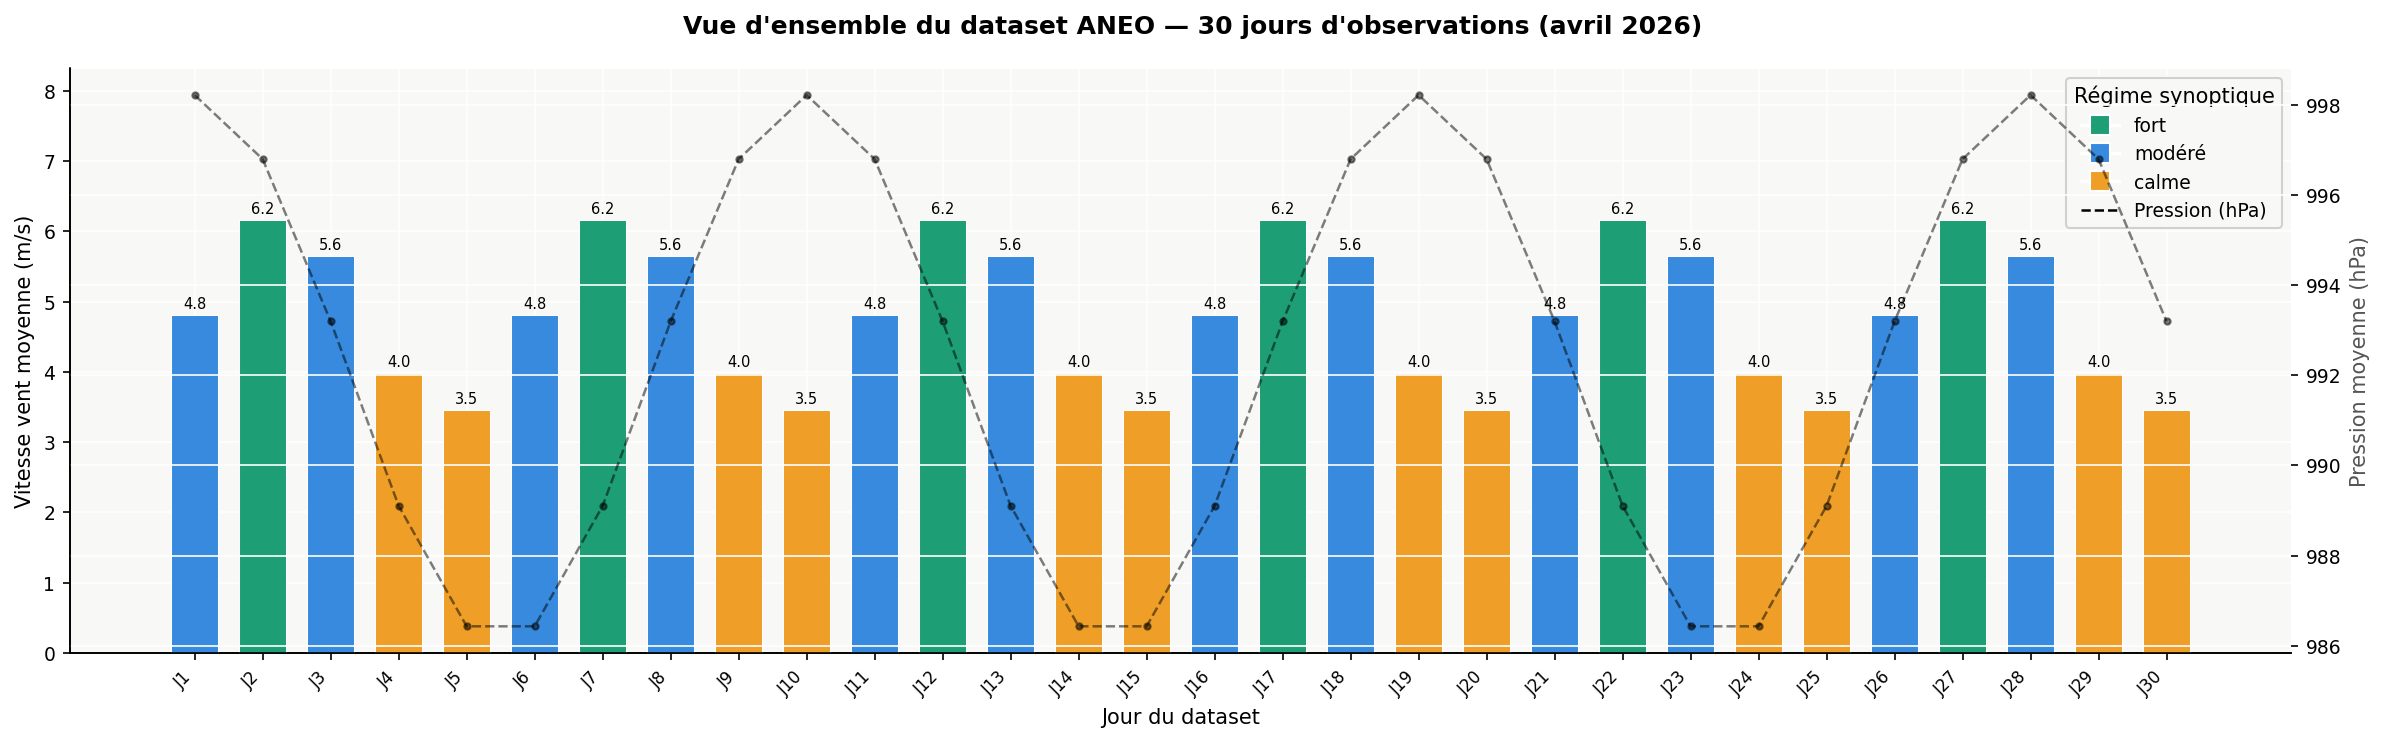

In [9]:
# ── Figure 01 : vitesse vent moyenne par jour + pression ──────────────────────
days = meta.index.tolist()
ws   = meta["ws_mean"].values
P    = meta["P_mean"].values
cols = [PALETTE_REGIME[r] for r in meta["regime"]]

fig, ax1 = plt.subplots(figsize=(16, 5))
fig.suptitle(
    "Vue d'ensemble du dataset ANEO — 30 jours d'observations (avril 2026)",
    fontsize=12, fontweight="bold"
)

# Barres vitesse vent
bars = ax1.bar(days, ws, color=cols, width=0.7,
               edgecolor="white", linewidth=0.5, zorder=3)
ax1.set_xlabel("Jour du dataset")
ax1.set_ylabel("Vitesse vent moyenne (m/s)")
ax1.set_xticks(days)
ax1.set_xticklabels([f"J{d}" for d in days], rotation=45,
                    ha="right", fontsize=8)
ax1.set_ylim(0, max(ws) * 1.35)

# Valeur au dessus de chaque barre
for bar, w in zip(bars, ws):
    ax1.text(bar.get_x() + bar.get_width() / 2,
             bar.get_height() + 0.05,
             f"{w:.1f}", ha="center", va="bottom", fontsize=7)

# Courbe pression axe secondaire
ax2 = ax1.twinx()
ax2.plot(days, P / 100, "k--o", lw=1.2, markersize=3,
         alpha=0.5, label="Pression (hPa)")
ax2.set_ylabel("Pression moyenne (hPa)", color="#555")

# Légende
handles = [
    Line2D([0], [0], marker="s", color="w",
           markerfacecolor=v, markersize=10, label=k)
    for k, v in PALETTE_REGIME.items()
]
handles.append(Line2D([0], [0], color="k", ls="--",
                      lw=1.2, label="Pression (hPa)"))
ax1.legend(handles=handles, loc="upper right", fontsize=9,
           title="Régime synoptique")

plt.tight_layout()
plt.savefig(OUT_DIR / "01_calendar_30days.png", dpi=150,
            bbox_inches="tight", facecolor="white")
plt.show()

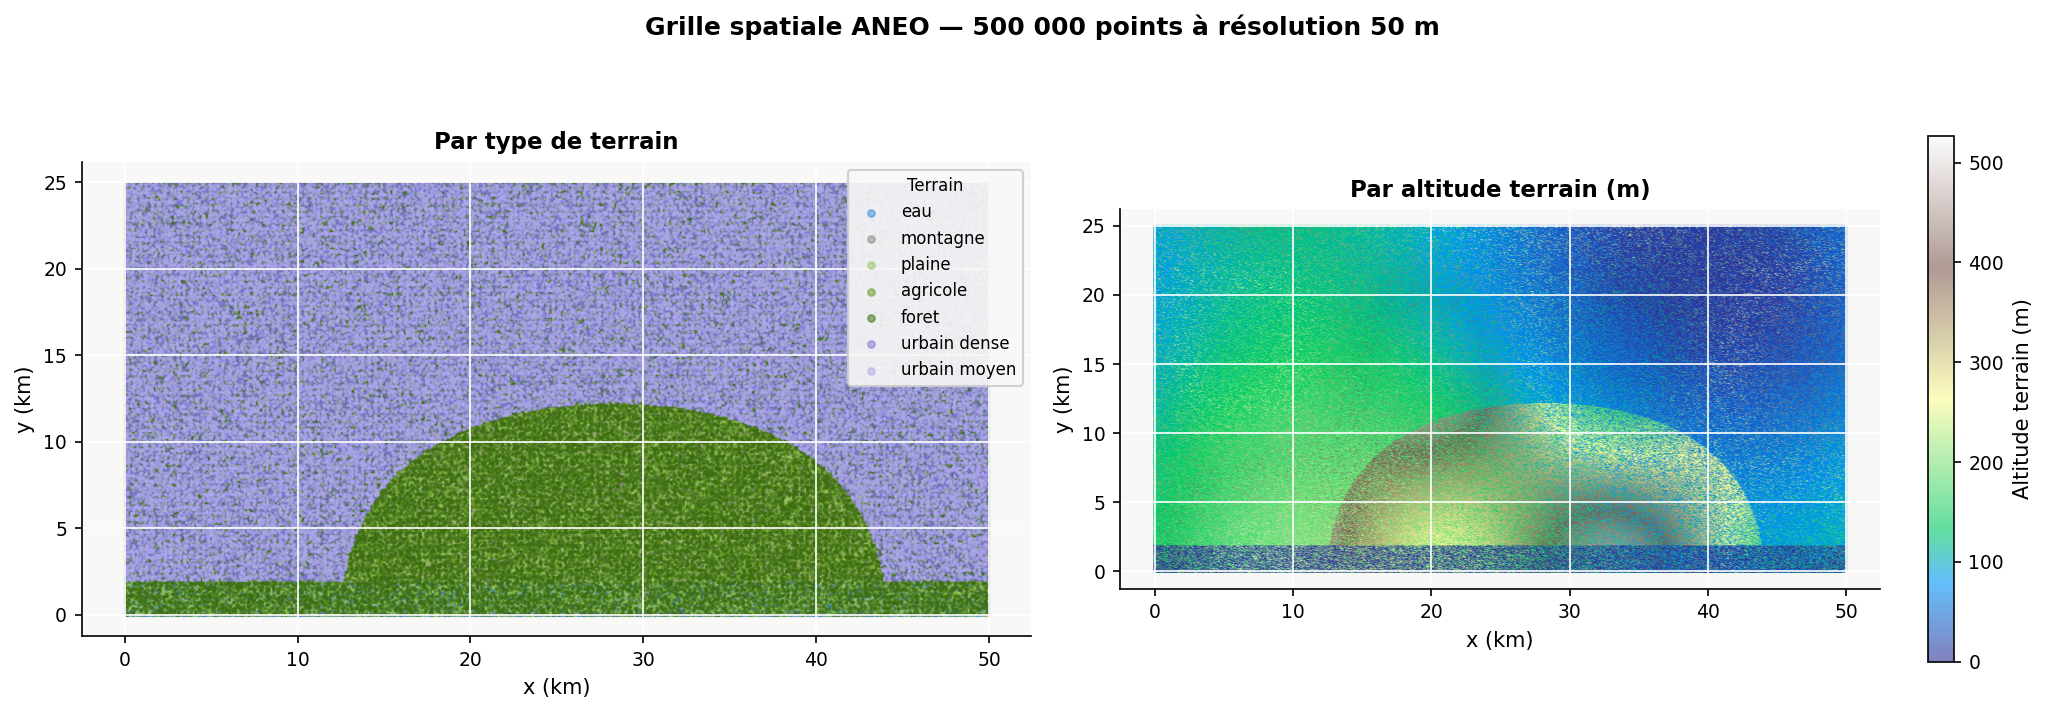

In [10]:
# ── Figure 02 : carte 2D de la grille colorée par terrain + altitude ──────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("Grille spatiale ANEO — 500 000 points à résolution 50 m",
             fontsize=12, fontweight="bold")

# ── Gauche : couleur par type de terrain ─────────────────────────────────────
ax = axes[0]
for terrain, color in PALETTE_TERRAIN.items():
    mask = grid["terrain_type"] == terrain
    ax.scatter(
        grid.loc[mask, "x_m"] / 1000,
        grid.loc[mask, "y_m"] / 1000,
        c=color, s=0.3, alpha=0.5,
        label=terrain.replace("_", " "),
        rasterized=True
    )
ax.set_xlabel("x (km)")
ax.set_ylabel("y (km)")
ax.set_title("Par type de terrain")
ax.set_aspect("equal")
ax.legend(markerscale=6, fontsize=8, loc="upper right",
          title="Terrain", title_fontsize=8)

# ── Droite : couleur par altitude ────────────────────────────────────────────
ax2 = axes[1]
sc = ax2.scatter(
    grid["x_m"] / 1000,
    grid["y_m"] / 1000,
    c=grid["z_terrain_m"],
    cmap="terrain",
    s=0.3, alpha=0.6,
    rasterized=True
)
plt.colorbar(sc, ax=ax2, label="Altitude terrain (m)", shrink=0.8)
ax2.set_xlabel("x (km)")
ax2.set_ylabel("y (km)")
ax2.set_title("Par altitude terrain (m)")
ax2.set_aspect("equal")

plt.tight_layout()
plt.savefig(OUT_DIR / "02_grid_map.png", dpi=150,
            bbox_inches="tight", facecolor="white")
plt.show()

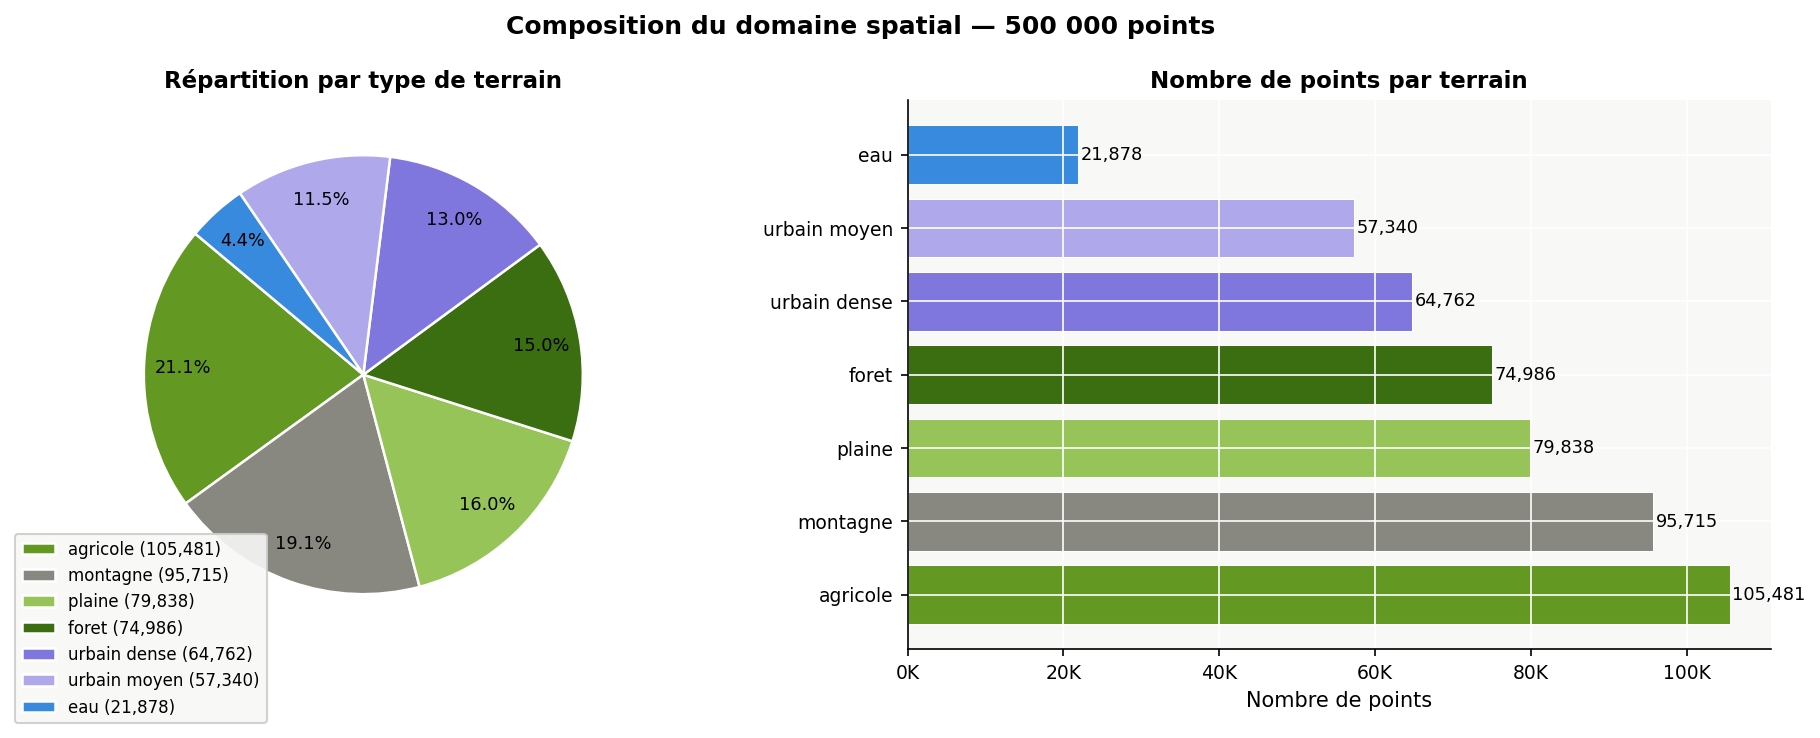

In [11]:
# ── Figure 03 : répartition des types de terrain ─────────────────────────────
counts = grid["terrain_type"].value_counts()
colors = [PALETTE_TERRAIN.get(t, "#999") for t in counts.index]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
fig.suptitle("Composition du domaine spatial — 500 000 points",
             fontsize=12, fontweight="bold")

# ── Pie chart ────────────────────────────────────────────────────────────────
ax = axes[0]
wedges, texts, autotexts = ax.pie(
    counts.values,
    labels=None,
    colors=colors,
    autopct="%1.1f%%",
    startangle=140,
    pctdistance=0.82,
    wedgeprops={"edgecolor": "white", "linewidth": 1.2}
)
for at in autotexts:
    at.set_fontsize(8.5)
ax.legend(
    wedges,
    [f"{t.replace('_', ' ')} ({n:,})"
     for t, n in zip(counts.index, counts.values)],
    loc="lower left", fontsize=8,
    bbox_to_anchor=(-0.15, -0.15)
)
ax.set_title("Répartition par type de terrain")

# ── Barplot horizontal ───────────────────────────────────────────────────────
ax2 = axes[1]
y = range(len(counts))
ax2.barh(y, counts.values, color=colors,
         edgecolor="white", linewidth=0.5)
ax2.set_yticks(y)
ax2.set_yticklabels(
    [t.replace("_", " ") for t in counts.index], fontsize=9
)
ax2.set_xlabel("Nombre de points")
ax2.set_title("Nombre de points par terrain")
ax2.xaxis.set_major_formatter(
    mticker.FuncFormatter(lambda v, _: f"{int(v/1000)}K")
)
for i, val in enumerate(counts.values):
    ax2.text(val + 300, i, f"{val:,}", va="center", fontsize=8.5)

plt.tight_layout()
plt.savefig(OUT_DIR / "03_terrain_composition.png", dpi=150,
            bbox_inches="tight", facecolor="white")
plt.show()

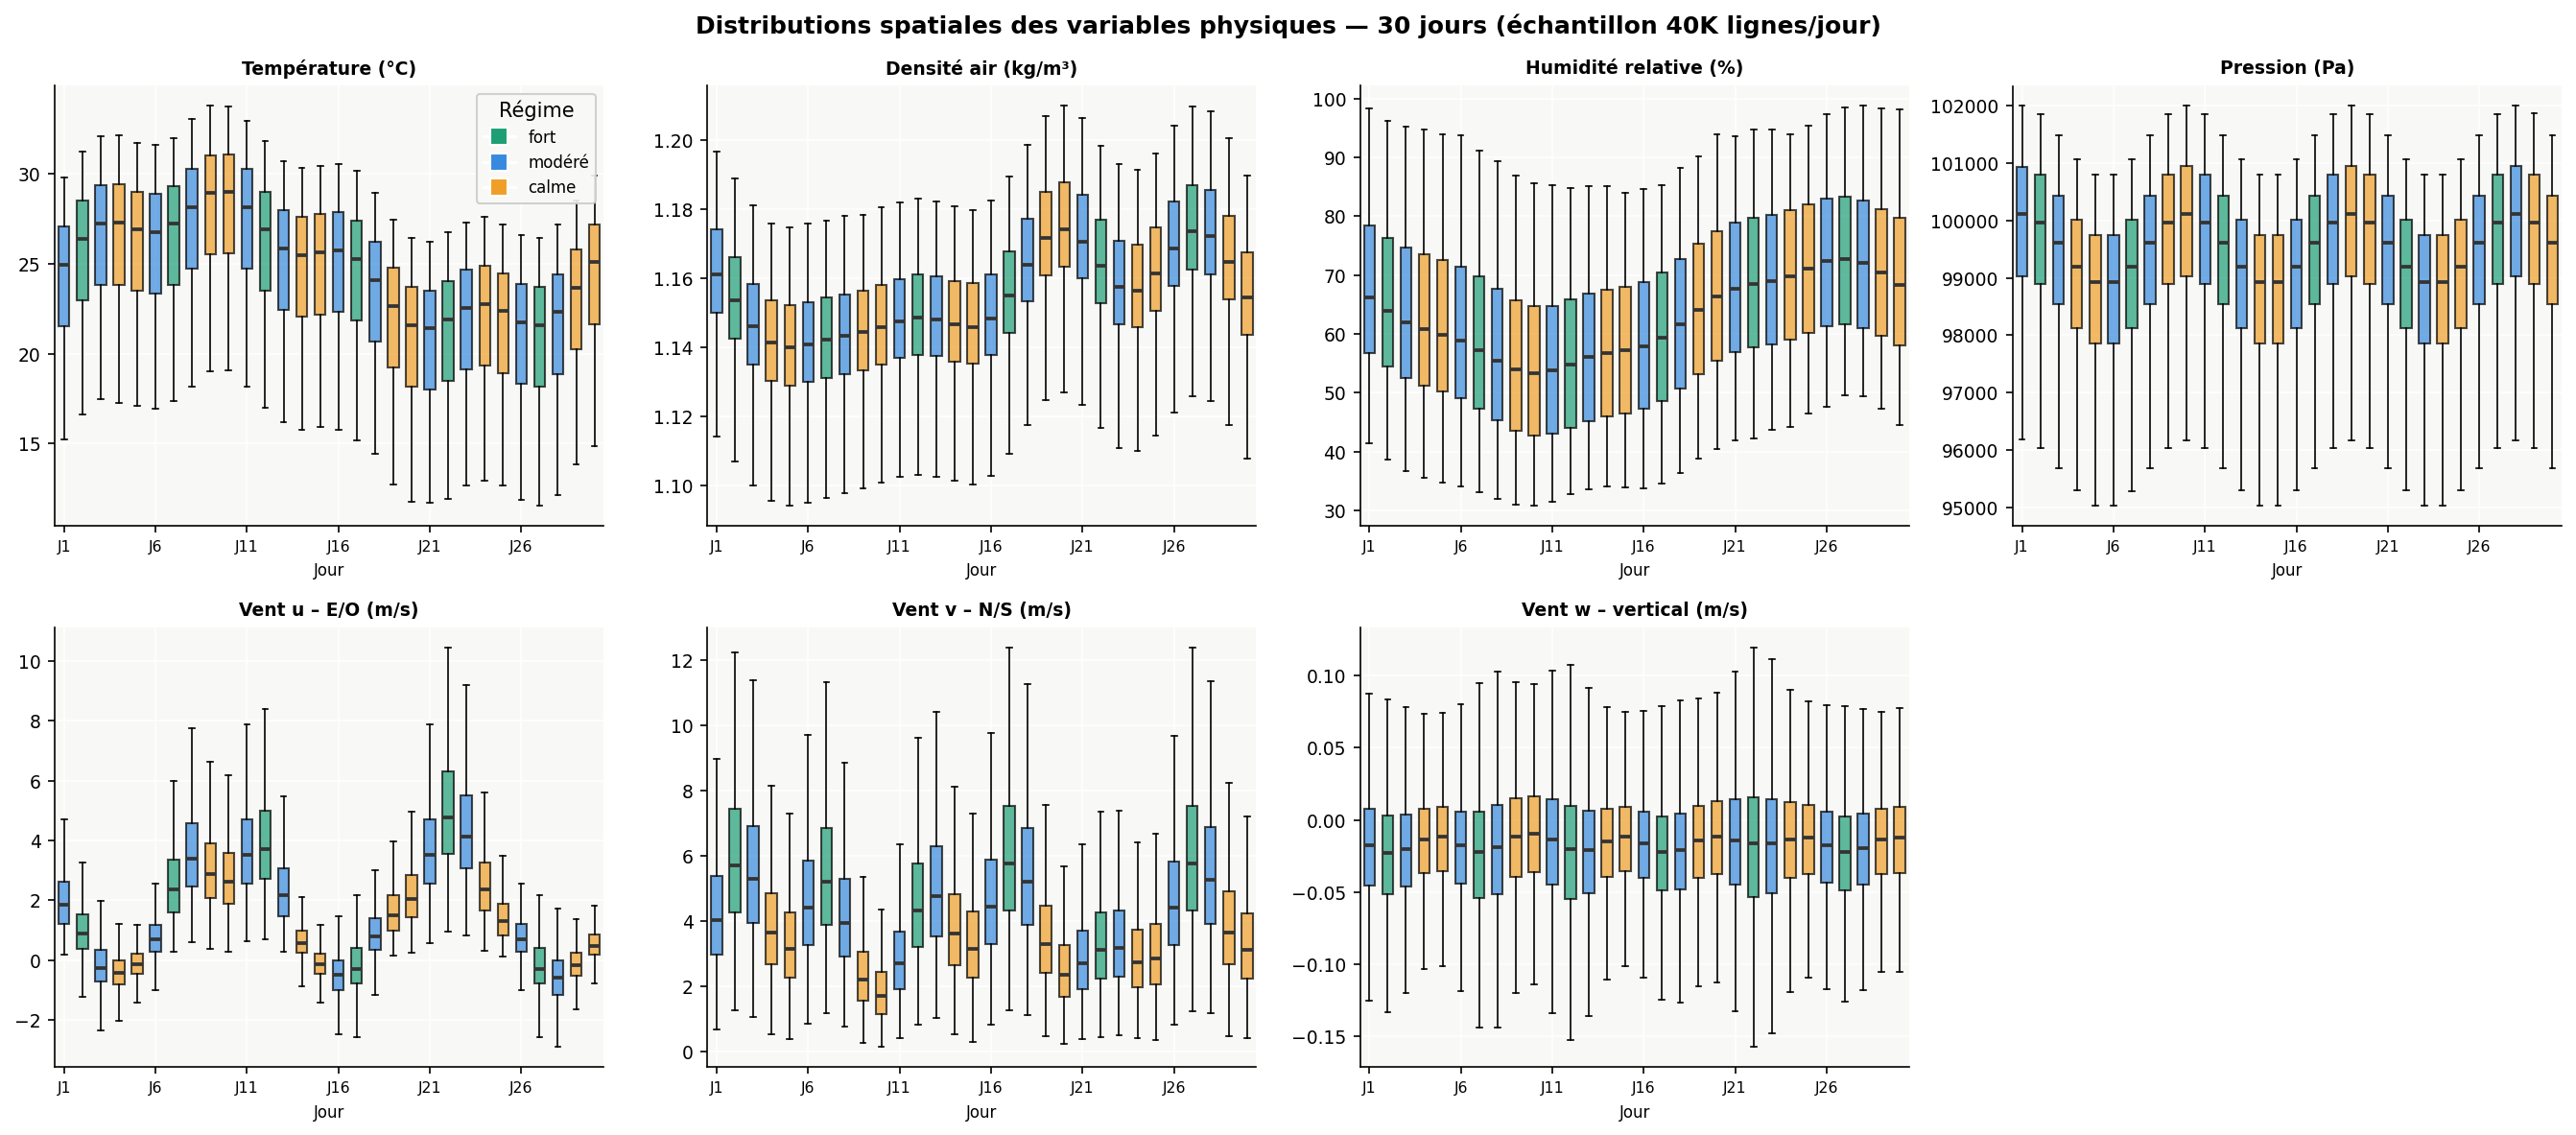

In [12]:
# ── Figure 04 : boxplots des 7 variables physiques × 30 jours ────────────────
sample_frames = []
for day, df in obs_dict.items():
    samp = df.sample(n=min(40_000, len(df)), random_state=42)[
        PHYS_COLS + ["day"]
    ]
    sample_frames.append(samp)
df_all = pd.concat(sample_frames, ignore_index=True)

days_sorted = sorted(obs_dict.keys())

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
fig.suptitle(
    "Distributions spatiales des variables physiques — 30 jours "
    "(échantillon 40K lignes/jour)",
    fontsize=12, fontweight="bold"
)
axes = axes.flatten()

for i, col in enumerate(PHYS_COLS):
    ax = axes[i]
    data_per_day = [
        df_all[df_all["day"] == d][col].dropna().values
        for d in days_sorted
    ]
    colors_bp = [
        PALETTE_REGIME[meta.loc[d, "regime"]] for d in days_sorted
    ]

    bp = ax.boxplot(
        data_per_day,
        positions=days_sorted,
        widths=0.6,
        patch_artist=True,
        showfliers=False,
        medianprops={"color": "#333", "lw": 1.8},
        whiskerprops={"lw": 0.8},
        capprops={"lw": 0.8},
    )
    for patch, c in zip(bp["boxes"], colors_bp):
        patch.set_facecolor(c)
        patch.set_alpha(0.70)

    ax.set_title(PHYS_LABELS[col], fontsize=9)
    ax.set_xlabel("Jour", fontsize=8)

    tick_days = days_sorted[::5]
    ax.set_xticks(tick_days)
    ax.set_xticklabels([f"J{d}" for d in tick_days], fontsize=7.5)

# Légende régimes
handles = [
    Line2D([0], [0], marker="s", color="w",
           markerfacecolor=v, markersize=9, label=k)
    for k, v in PALETTE_REGIME.items()
]
axes[0].legend(handles=handles, loc="upper right",
               fontsize=8, title="Régime")

axes[-1].set_visible(False)

plt.tight_layout()
plt.savefig(OUT_DIR / "04_descriptive_stats.png", dpi=150,
            bbox_inches="tight", facecolor="white")
plt.show()

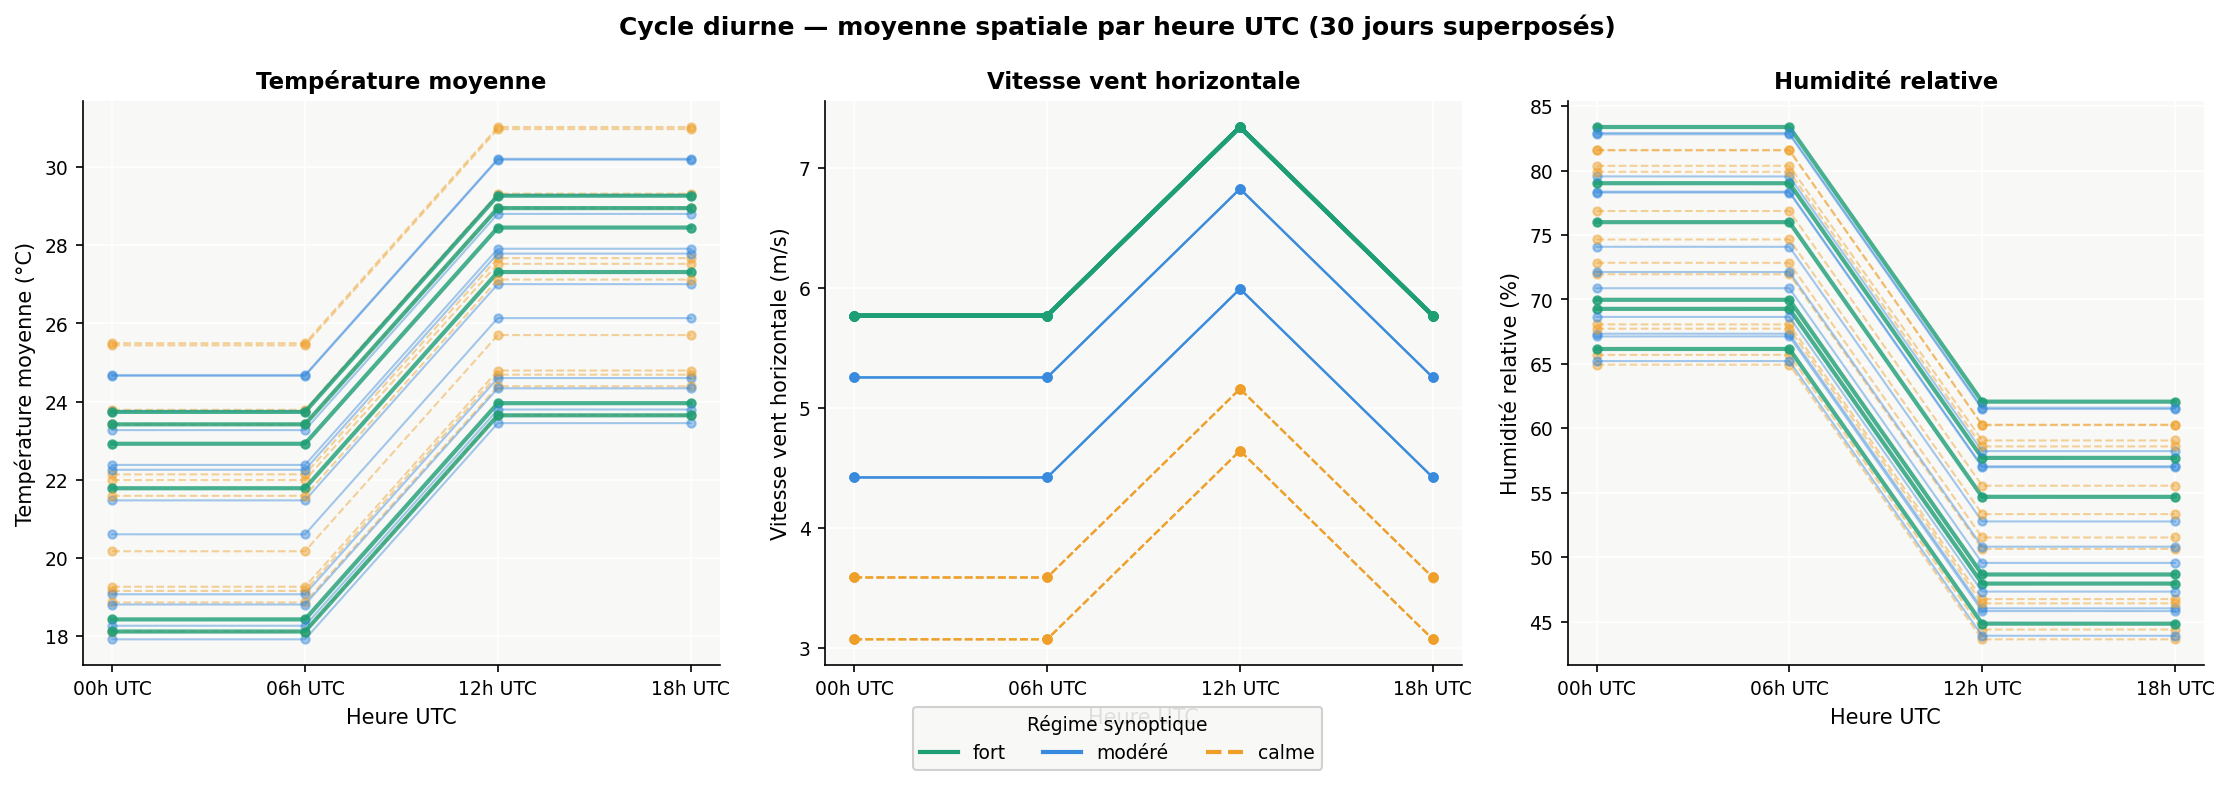

In [13]:
# ── Figure 05 : cycle diurne — moyenne spatiale par heure UTC ─────────────────
hours = [0, 6, 12, 18]
vars_plot = [
    ("temperature_c",         "Température moyenne (°C)"),
    ("wind_speed_h",          "Vitesse vent horizontale (m/s)"),
    ("relative_humidity_pct", "Humidité relative (%)"),
]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.suptitle(
    "Cycle diurne — moyenne spatiale par heure UTC (30 jours superposés)",
    fontsize=12, fontweight="bold"
)

for ax, (col, ylabel) in zip(axes, vars_plot):
    for day, df in obs_dict.items():
        regime = meta.loc[day, "regime"]
        color  = PALETTE_REGIME[regime]
        lw     = 2.0 if regime == "fort" else 1.0
        ls     = "-" if regime != "calme" else "--"
        alpha  = 0.80 if regime == "fort" else 0.45

        hmeans = df.groupby("hour_utc")[col].mean()
        vals   = [hmeans.get(h, np.nan) for h in hours]

        ax.plot(hours, vals, color=color, lw=lw, ls=ls,
                alpha=alpha, marker="o", markersize=4)

    ax.set_xticks(hours)
    ax.set_xticklabels([f"{h:02d}h UTC" for h in hours])
    ax.set_xlabel("Heure UTC")
    ax.set_ylabel(ylabel)
    ax.set_title(ylabel.split("(")[0].strip())

# Légende régimes
handles = [
    Line2D([0], [0], color=v, lw=2,
           ls="-" if k != "calme" else "--", label=k)
    for k, v in PALETTE_REGIME.items()
]
fig.legend(handles=handles, loc="lower center", ncol=3,
           fontsize=9, bbox_to_anchor=(0.5, -0.04),
           title="Régime synoptique", title_fontsize=9)

plt.tight_layout()
plt.savefig(OUT_DIR / "05_diurnal_cycle.png", dpi=150,
            bbox_inches="tight", facecolor="white")
plt.show()

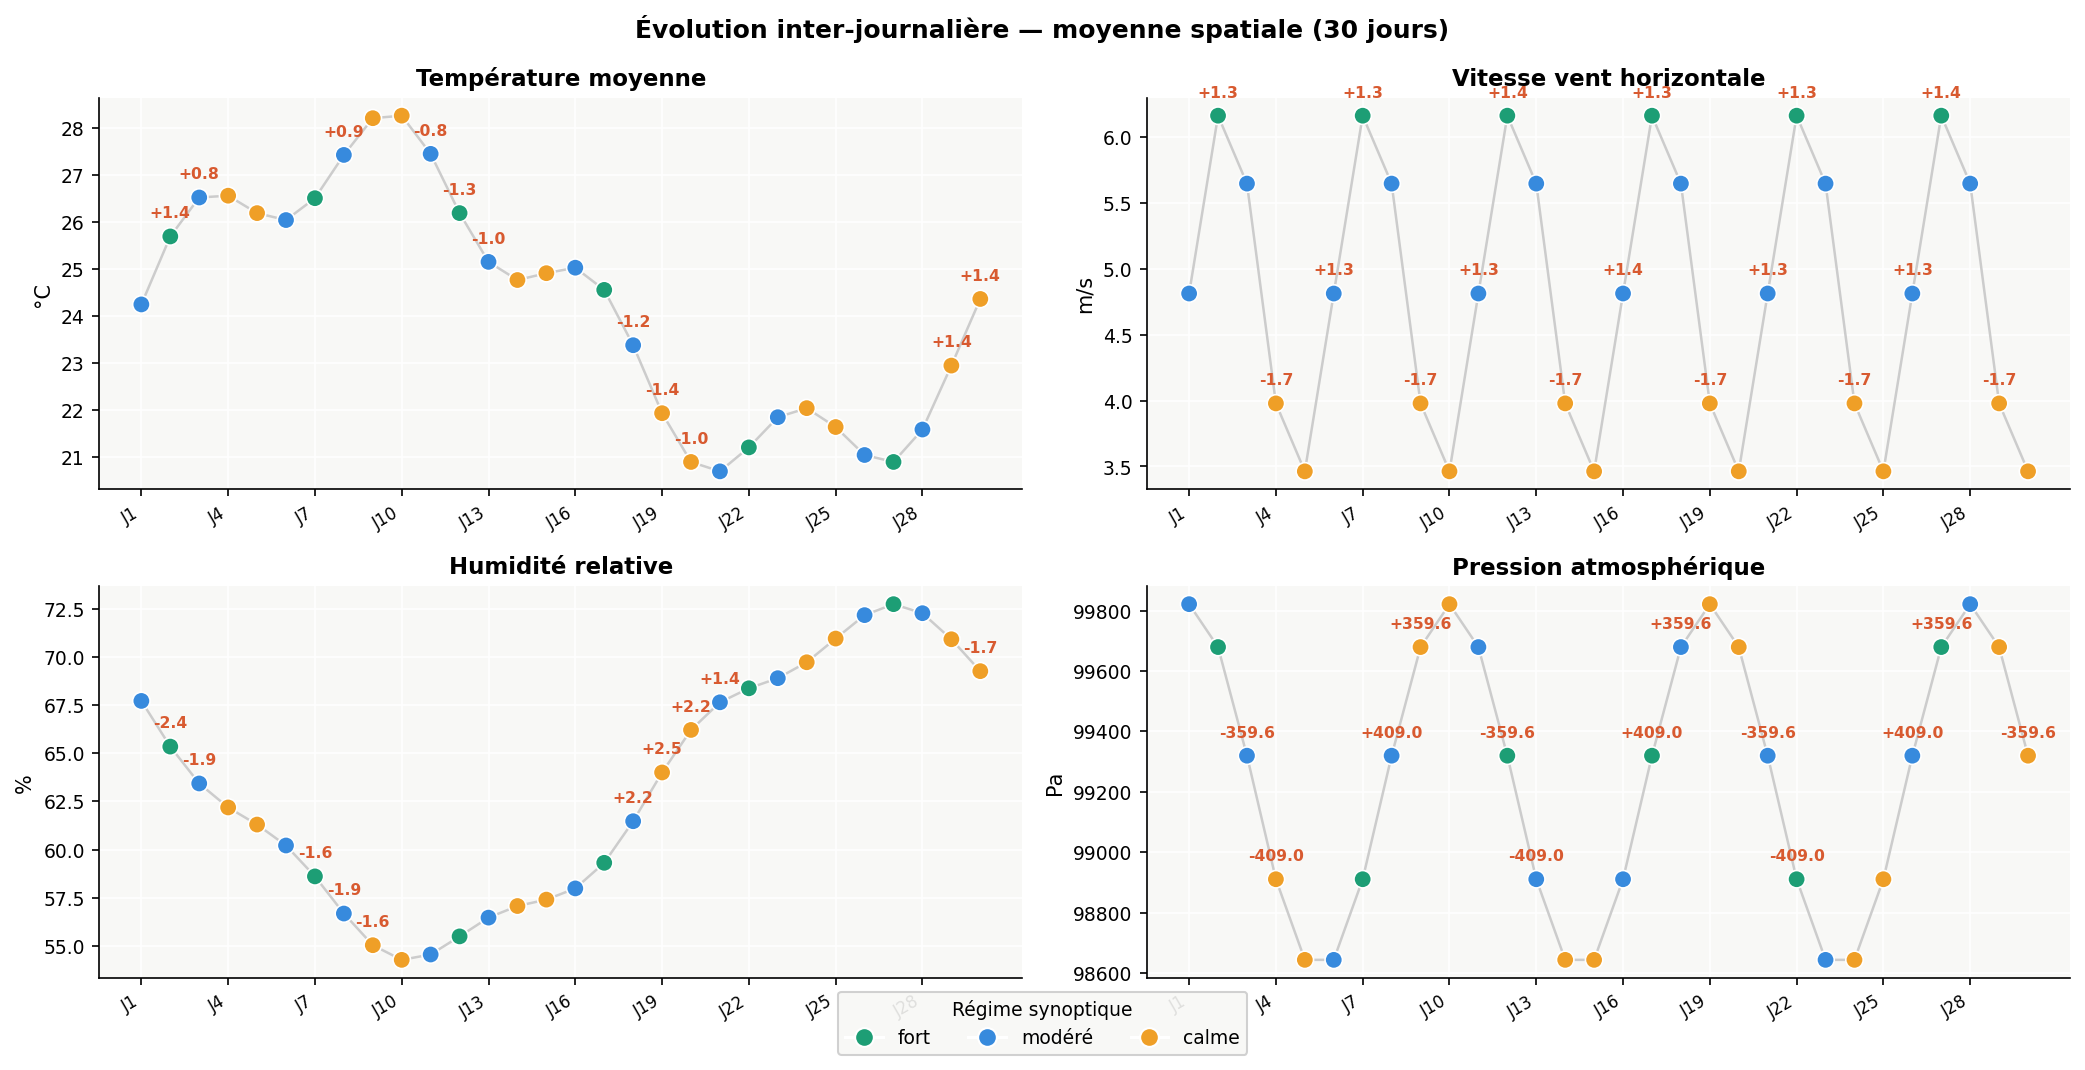

In [15]:
# ── Figure 06 : évolution jour par jour de T, vent, RH, pression ─────────────
days   = meta.index.tolist()
x      = range(len(days))
xlbl   = [f"J{d}" for d in days]
reg_c  = [PALETTE_REGIME[meta.loc[d, "regime"]] for d in days]

fig, axes = plt.subplots(2, 2, figsize=(14, 7))
fig.suptitle(
    "Évolution inter-journalière — moyenne spatiale (30 jours)",
    fontsize=12, fontweight="bold"
)

vars_ev = [
    ("T_mean",  "°C",  "Température moyenne"),
    ("ws_mean", "m/s", "Vitesse vent horizontale"),
    ("RH_mean", "%",   "Humidité relative"),
    ("P_mean",  "Pa",  "Pression atmosphérique"),
]

for ax, (col, unit, title) in zip(axes.flatten(), vars_ev):
    vals = meta[col].values

    # Ligne de connexion grise
    ax.plot(x, vals, "-", color="#ccc", lw=1.2, zorder=2)

    # Points colorés par régime
    ax.scatter(x, vals, c=reg_c, s=70, zorder=4,
               edgecolors="white", lw=0.8)

    ax.set_xticks(list(x)[::3])
    ax.set_xticklabels(xlbl[::3], fontsize=8,
                       rotation=30, ha="right")
    ax.set_ylabel(unit)
    ax.set_title(title)

    # Annoter les grands sauts uniquement
    std_val = np.std(np.diff(vals))
    for i in range(1, len(vals)):
        delta = vals[i] - vals[i - 1]
        if abs(delta) > std_val:
            sign = "+" if delta >= 0 else ""
            ax.annotate(
                f"{sign}{delta:.1f}",
                xy=(i, vals[i]),
                xytext=(0, 9),
                textcoords="offset points",
                ha="center", fontsize=7.5,
                color="#D85A30", fontweight="bold"
            )

# Légende régimes
handles = [
    Line2D([0], [0], marker="o", color="w",
           markerfacecolor=v, markersize=9, label=k)
    for k, v in PALETTE_REGIME.items()
]
fig.legend(handles=handles, loc="lower center", ncol=3,
           fontsize=9, bbox_to_anchor=(0.5, -0.02),
           title="Régime synoptique", title_fontsize=9)

plt.tight_layout()
plt.savefig(OUT_DIR / "06_temporal_evolution.png", dpi=150,
            bbox_inches="tight", facecolor="white")
plt.show()

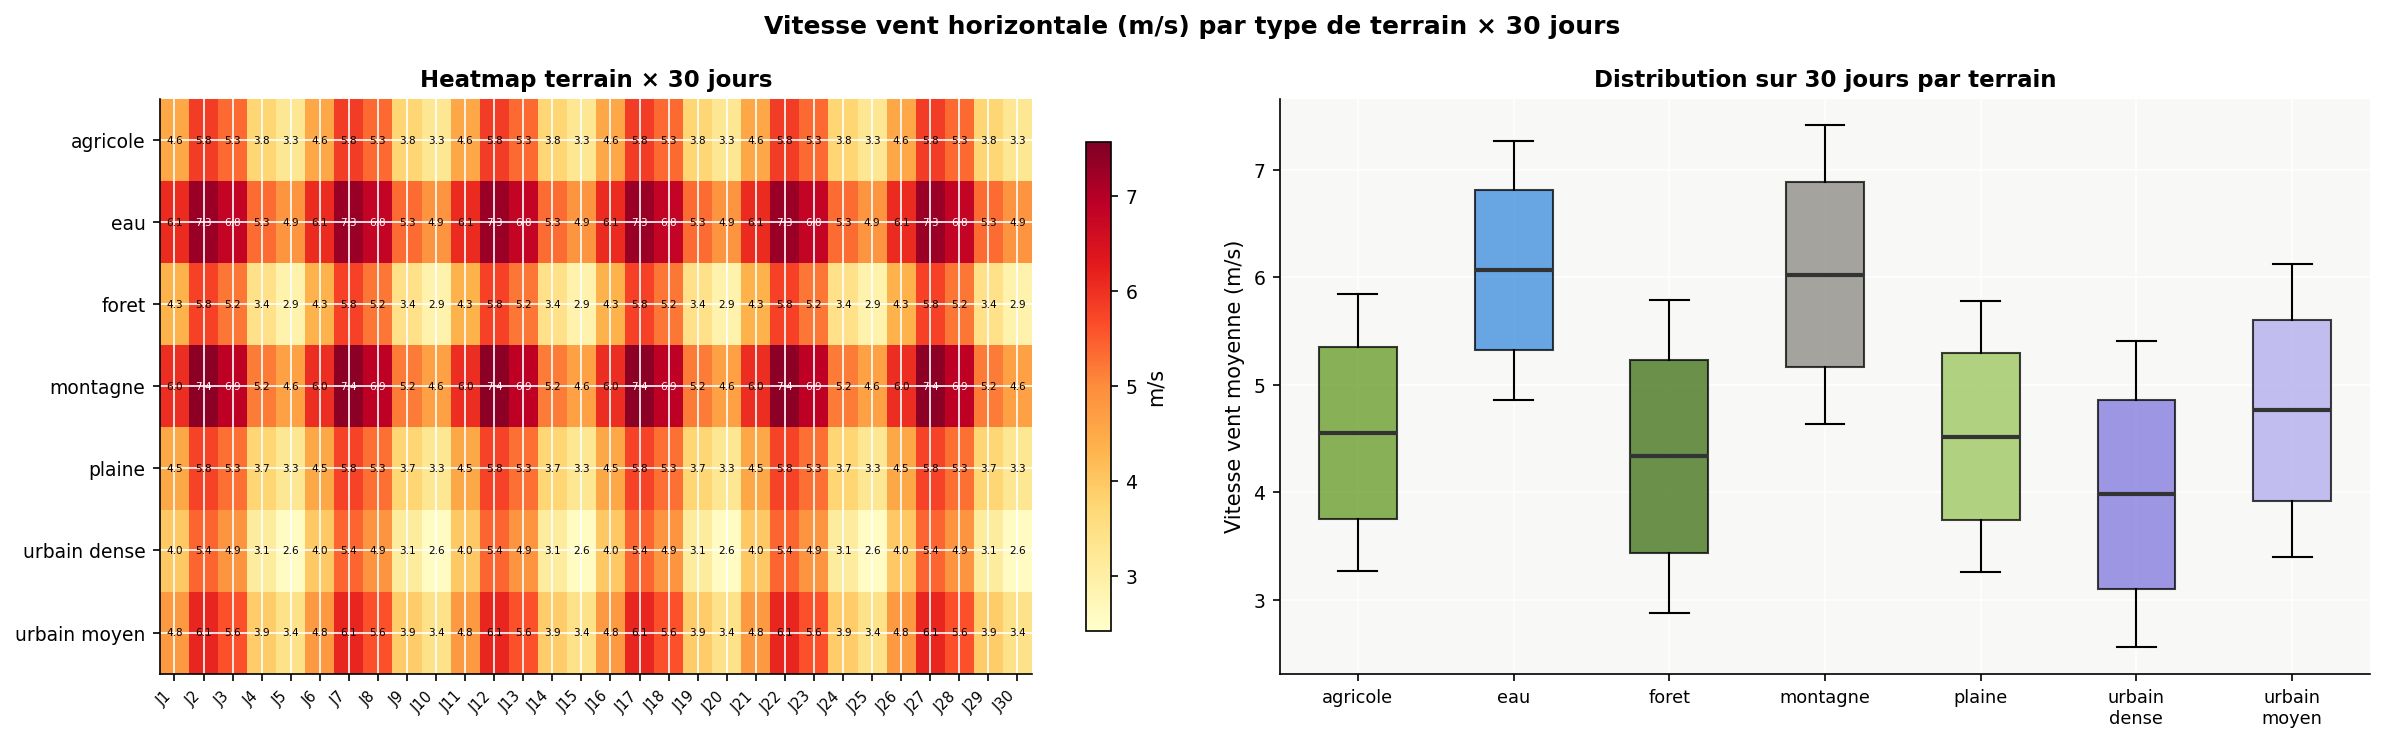

In [16]:
# ── Figure 07 : heatmap vitesse vent × terrain × 30 jours ────────────────────
g = grid[["point_id", "terrain_type"]]

records = []
for day, df in obs_dict.items():
    merged = df.merge(g, on="point_id")
    tw = merged.groupby("terrain_type")["wind_speed_h"].mean()
    tw.name = day
    records.append(tw)

tw_df = pd.DataFrame(records).T
tw_df.columns = [f"J{d}" for d in tw_df.columns]

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
fig.suptitle(
    "Vitesse vent horizontale (m/s) par type de terrain × 30 jours",
    fontsize=12, fontweight="bold"
)

# ── Heatmap complète ──────────────────────────────────────────────────────────
ax = axes[0]
im = ax.imshow(
    tw_df.values, aspect="auto", cmap="YlOrRd",
    vmin=tw_df.values.min() * 0.95,
    vmax=tw_df.values.max() * 1.02
)
ax.set_xticks(range(len(tw_df.columns)))
ax.set_xticklabels(tw_df.columns, rotation=45,
                   ha="right", fontsize=7)
ax.set_yticks(range(len(tw_df.index)))
ax.set_yticklabels(
    [t.replace("_", " ") for t in tw_df.index], fontsize=9
)
ax.set_title("Heatmap terrain × 30 jours")
plt.colorbar(im, ax=ax, label="m/s", shrink=0.85)

for i in range(tw_df.shape[0]):
    for j in range(tw_df.shape[1]):
        v = tw_df.values[i, j]
        ax.text(j, i, f"{v:.1f}", ha="center", va="center",
                fontsize=5,
                color="white" if v > 6.5 else "black")

# ── Boxplot distribution sur 30 jours par terrain ────────────────────────────
ax2 = axes[1]
terrains  = list(tw_df.index)
data_box  = [tw_df.loc[t].values for t in terrains]
colors_bp = [PALETTE_TERRAIN.get(t, "#999") for t in terrains]

bp = ax2.boxplot(
    data_box,
    patch_artist=True,
    showfliers=True,
    medianprops={"color": "#333", "lw": 2},
    flierprops={"marker": ".", "markersize": 4, "alpha": 0.5},
)
for patch, c in zip(bp["boxes"], colors_bp):
    patch.set_facecolor(c)
    patch.set_alpha(0.75)

ax2.set_xticks(range(1, len(terrains) + 1))
ax2.set_xticklabels(
    [t.replace("_", "\n") for t in terrains], fontsize=8.5
)
ax2.set_ylabel("Vitesse vent moyenne (m/s)")
ax2.set_title("Distribution sur 30 jours par terrain")

plt.tight_layout()
plt.savefig(OUT_DIR / "07_wind_by_terrain.png", dpi=150,
            bbox_inches="tight", facecolor="white")
plt.show()

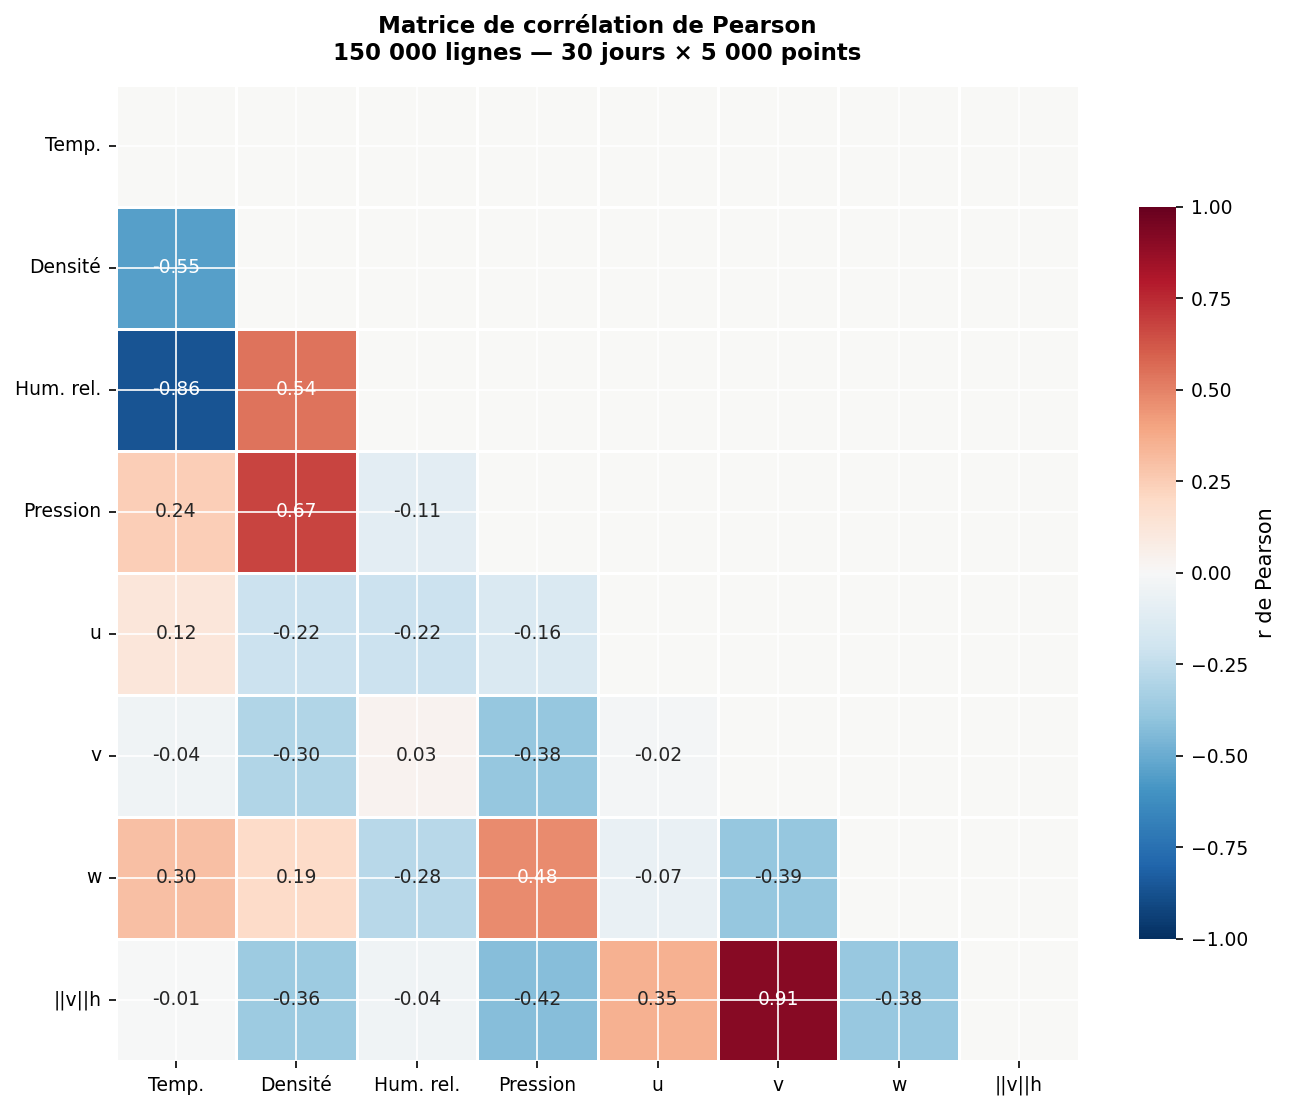

In [17]:
# ── Figure 08 : matrice de corrélation de Pearson — 30 jours poolés ──────────
frames = []
for day, df in obs_dict.items():
    samp = df.sample(n=5_000, random_state=42)[PHYS_COLS + ["wind_speed_h"]]
    frames.append(samp)
df_pool = pd.concat(frames, ignore_index=True)

cols_corr   = PHYS_COLS + ["wind_speed_h"]
labels_corr = [
    "Temp.", "Densité", "Hum. rel.", "Pression",
    "u", "v", "w", "||v||h"
]

corr = df_pool[cols_corr].corr()

fig, ax = plt.subplots(figsize=(9, 7.5))
mask = np.triu(np.ones_like(corr, dtype=bool))

sns.heatmap(
    corr, mask=mask, annot=True, fmt=".2f",
    cmap="RdBu_r", center=0, vmin=-1, vmax=1,
    linewidths=0.5, linecolor="white",
    xticklabels=labels_corr,
    yticklabels=labels_corr,
    ax=ax,
    cbar_kws={"shrink": 0.75, "label": "r de Pearson"},
    annot_kws={"size": 9},
)
ax.set_title(
    "Matrice de corrélation de Pearson\n"
    "150 000 lignes — 30 jours × 5 000 points",
    fontsize=11, fontweight="bold", pad=12
)
plt.xticks(rotation=0, fontsize=9)
plt.yticks(rotation=0, fontsize=9)
plt.tight_layout()
plt.savefig(OUT_DIR / "08_correlation_matrix.png", dpi=150,
            bbox_inches="tight", facecolor="white")
plt.show()

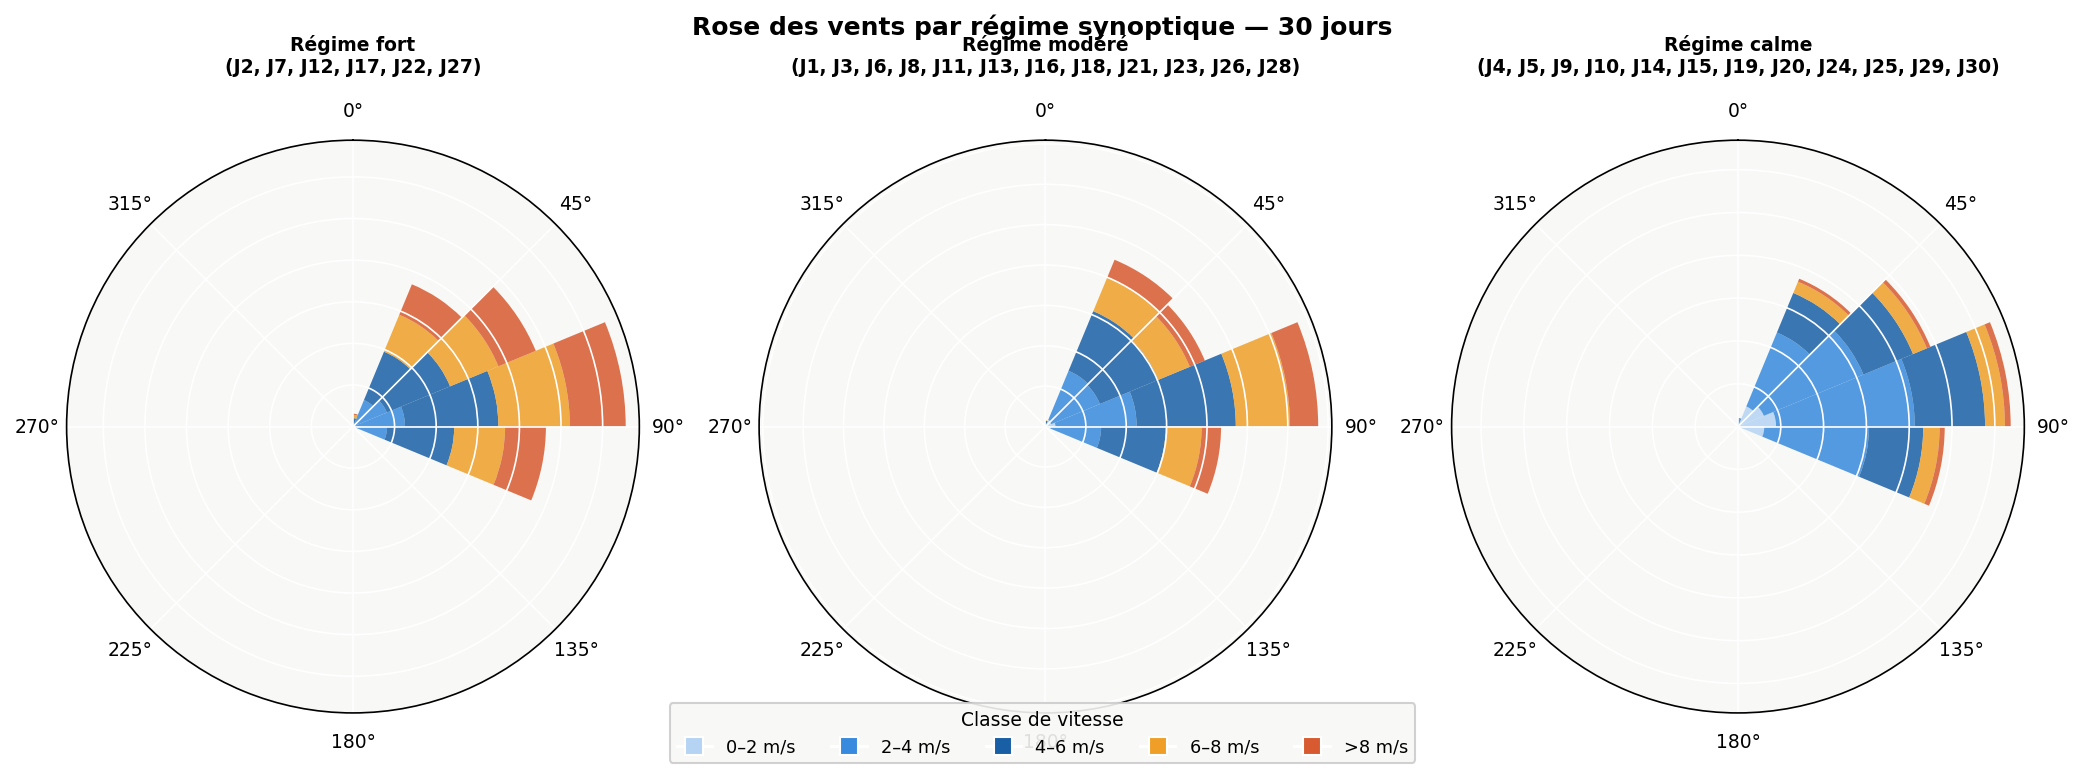

In [18]:
# ── Figure 09 : rose des vents par régime synoptique ─────────────────────────
regimes_days = {"fort": [], "modéré": [], "calme": []}
for day in obs_dict:
    regimes_days[meta.loc[day, "regime"]].append(day)

n_bins      = 16
theta_edges = np.linspace(0, 2 * np.pi, n_bins + 1)
speed_bins  = [0, 2, 4, 6, 8, 15]
speed_lbls  = ["0–2 m/s", "2–4 m/s", "4–6 m/s", "6–8 m/s", ">8 m/s"]
speed_cols  = ["#B5D4F4", "#378ADD", "#185FA5", "#EF9F27", "#D85A30"]

fig, axes = plt.subplots(
    1, 3, figsize=(14, 5),
    subplot_kw={"projection": "polar"}
)
fig.suptitle(
    "Rose des vents par régime synoptique — 30 jours",
    fontsize=12, fontweight="bold"
)

for ax, (regime, days_r) in zip(axes, regimes_days.items()):
    if not days_r:
        ax.set_visible(False)
        continue

    frames = []
    for d in days_r:
        samp = obs_dict[d].sample(
            n=min(30_000 // len(days_r), len(obs_dict[d])),
            random_state=42
        )
        frames.append(samp[["wind_speed_h", "wind_dir_deg"]])
    df_r = pd.concat(frames, ignore_index=True)

    dir_rad = np.radians(df_r["wind_dir_deg"].values)
    ws_vals = df_r["wind_speed_h"].values
    bottom  = np.zeros(n_bins)
    width   = 2 * np.pi / n_bins
    theta_c = theta_edges[:-1] + width / 2

    for si in range(len(speed_bins) - 1):
        mask = (ws_vals >= speed_bins[si]) & (ws_vals < speed_bins[si + 1])
        hist, _ = np.histogram(dir_rad[mask], bins=theta_edges)
        hist    = hist / len(df_r) * 100
        ax.bar(theta_c, hist, width=width, bottom=bottom,
               color=speed_cols[si], alpha=0.85)
        bottom += hist

    ax.set_theta_zero_location("N")
    ax.set_theta_direction(-1)
    days_str = ", ".join(f"J{d}" for d in days_r)
    ax.set_title(
        f"Régime {regime}\n({days_str})",
        fontsize=9, pad=14
    )
    ax.set_yticklabels([])

handles = [
    Line2D([0], [0], marker="s", color="w",
           markerfacecolor=c, markersize=9, label=l)
    for c, l in zip(speed_cols, speed_lbls)
]
fig.legend(handles=handles, loc="lower center", ncol=5,
           fontsize=8.5, bbox_to_anchor=(0.5, -0.03),
           title="Classe de vitesse", title_fontsize=9)

plt.tight_layout()
plt.savefig(OUT_DIR / "09_wind_roses.png", dpi=150,
            bbox_inches="tight", facecolor="white")
plt.show()

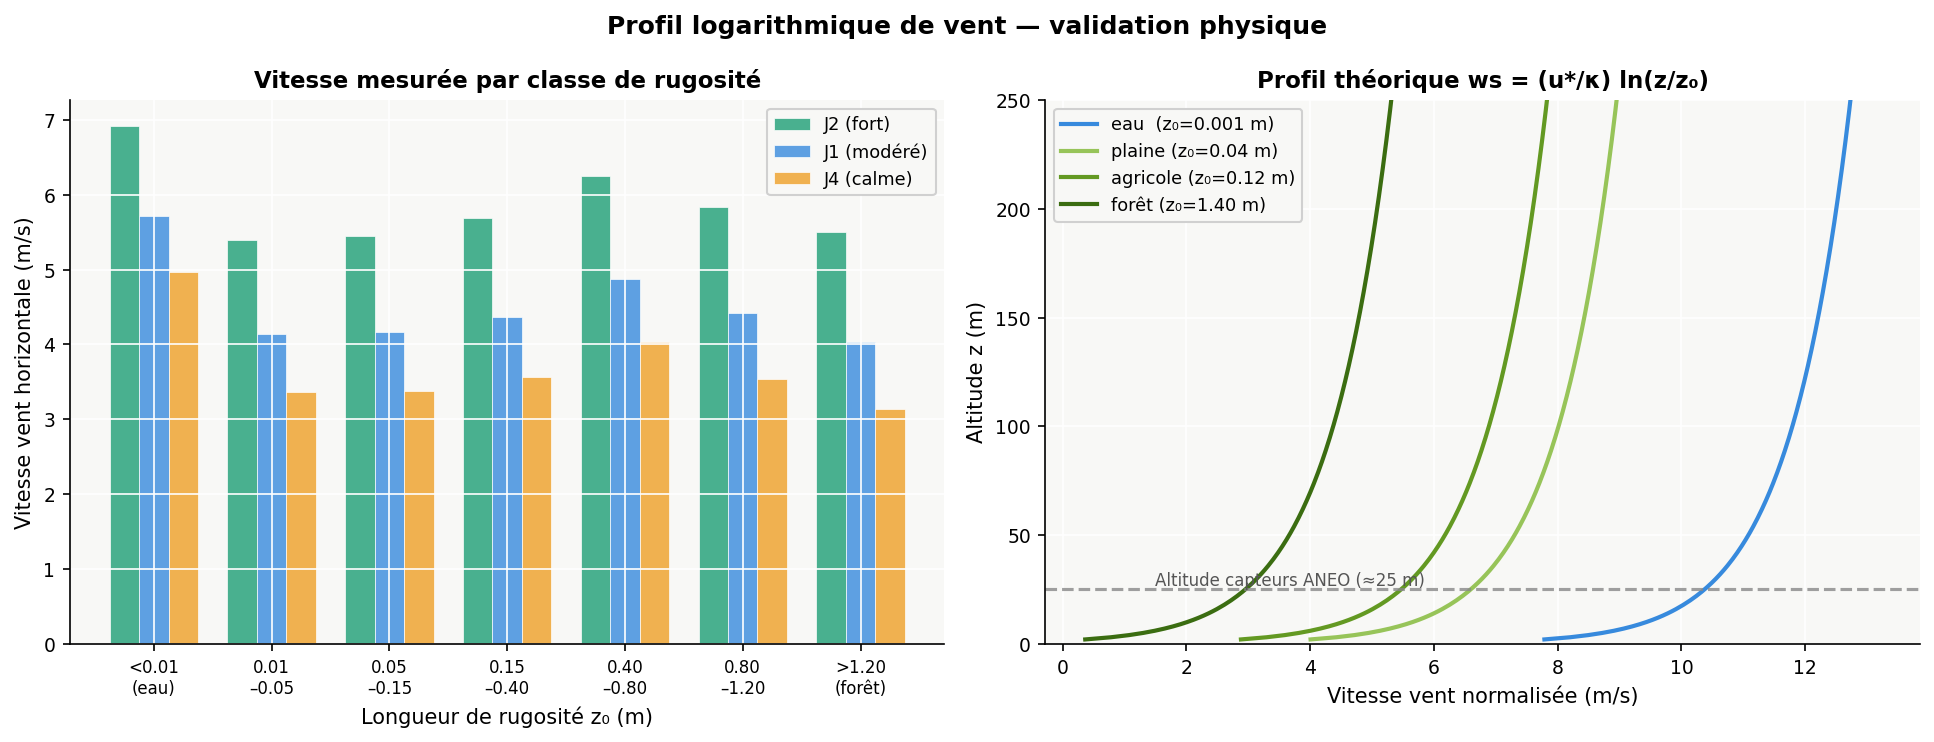

In [19]:
# ── Figure 10 : profil log-vent par rugosité z₀ ──────────────────────────────
g = grid[["point_id", "z_rel_m", "z0_m", "z_terrain_m"]]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
fig.suptitle(
    "Profil logarithmique de vent — validation physique",
    fontsize=12, fontweight="bold"
)

# ── Gauche : vitesse mesurée par classe de rugosité z₀ ───────────────────────
ax = axes[0]
z0_bins = [0, 0.01, 0.05, 0.15, 0.40, 0.80, 1.20, 2.50]
z0_lbls = ["<0.01\n(eau)", "0.01\n–0.05", "0.05\n–0.15",
           "0.15\n–0.40", "0.40\n–0.80", "0.80\n–1.20", ">1.20\n(forêt)"]

days_repr = {}
for regime in ["fort", "modéré", "calme"]:
    for day in sorted(obs_dict.keys()):
        if meta.loc[day, "regime"] == regime:
            days_repr[regime] = day
            break

x     = np.arange(len(z0_bins) - 1)
width = 0.25

for i, (regime, day) in enumerate(days_repr.items()):
    df_h0 = obs_dict[day][obs_dict[day]["hour_utc"] == 0].merge(g, on="point_id")
    df_h0["ws"]     = np.sqrt(df_h0["wind_u_m_s"]**2 + df_h0["wind_v_m_s"]**2)
    df_h0["z0_bin"] = pd.cut(df_h0["z0_m"], bins=z0_bins)
    means = df_h0.groupby("z0_bin", observed=True)["ws"].mean().values

    ax.bar(x + i * width, means, width,
           color=PALETTE_REGIME[regime], alpha=0.80,
           label=f"J{day} ({regime})",
           edgecolor="white", lw=0.4)

ax.set_xticks(x + width)
ax.set_xticklabels(z0_lbls, fontsize=8)
ax.set_xlabel("Longueur de rugosité z₀ (m)")
ax.set_ylabel("Vitesse vent horizontale (m/s)")
ax.set_title("Vitesse mesurée par classe de rugosité")
ax.legend(fontsize=8.5)

# ── Droite : profil théorique ws(z) = (u*/κ) ln(z/z₀) ──────────────────────
ax2 = axes[1]
z_vals = np.linspace(2, 400, 400)
u_star = 0.42
kappa  = 0.41

z0_cases = {
    "eau  (z₀=0.001 m)":    0.001,
    "plaine (z₀=0.04 m)":   0.04,
    "agricole (z₀=0.12 m)": 0.12,
    "forêt (z₀=1.40 m)":    1.40,
}
colors_case = ["#378ADD", "#97C459", "#639922", "#3B6D11"]

for (lbl, z0), color in zip(z0_cases.items(), colors_case):
    profile = (u_star / kappa) * np.log(np.maximum(z_vals / z0, 1.001))
    profile = np.clip(profile, 0, None)
    ax2.plot(profile, z_vals, lw=2, color=color, label=lbl)

ax2.axhline(y=25, color="#888", lw=1.5, ls="--", alpha=0.8)
ax2.text(1.5, 27, "Altitude capteurs ANEO (≈25 m)",
         fontsize=8, color="#555")
ax2.set_xlabel("Vitesse vent normalisée (m/s)")
ax2.set_ylabel("Altitude z (m)")
ax2.set_title("Profil théorique ws = (u*/κ) ln(z/z₀)")
ax2.legend(fontsize=8.5, loc="upper left")
ax2.set_ylim(0, 250)

plt.tight_layout()
plt.savefig(OUT_DIR / "10_log_wind_profile.png", dpi=150,
            bbox_inches="tight", facecolor="white")
plt.show()

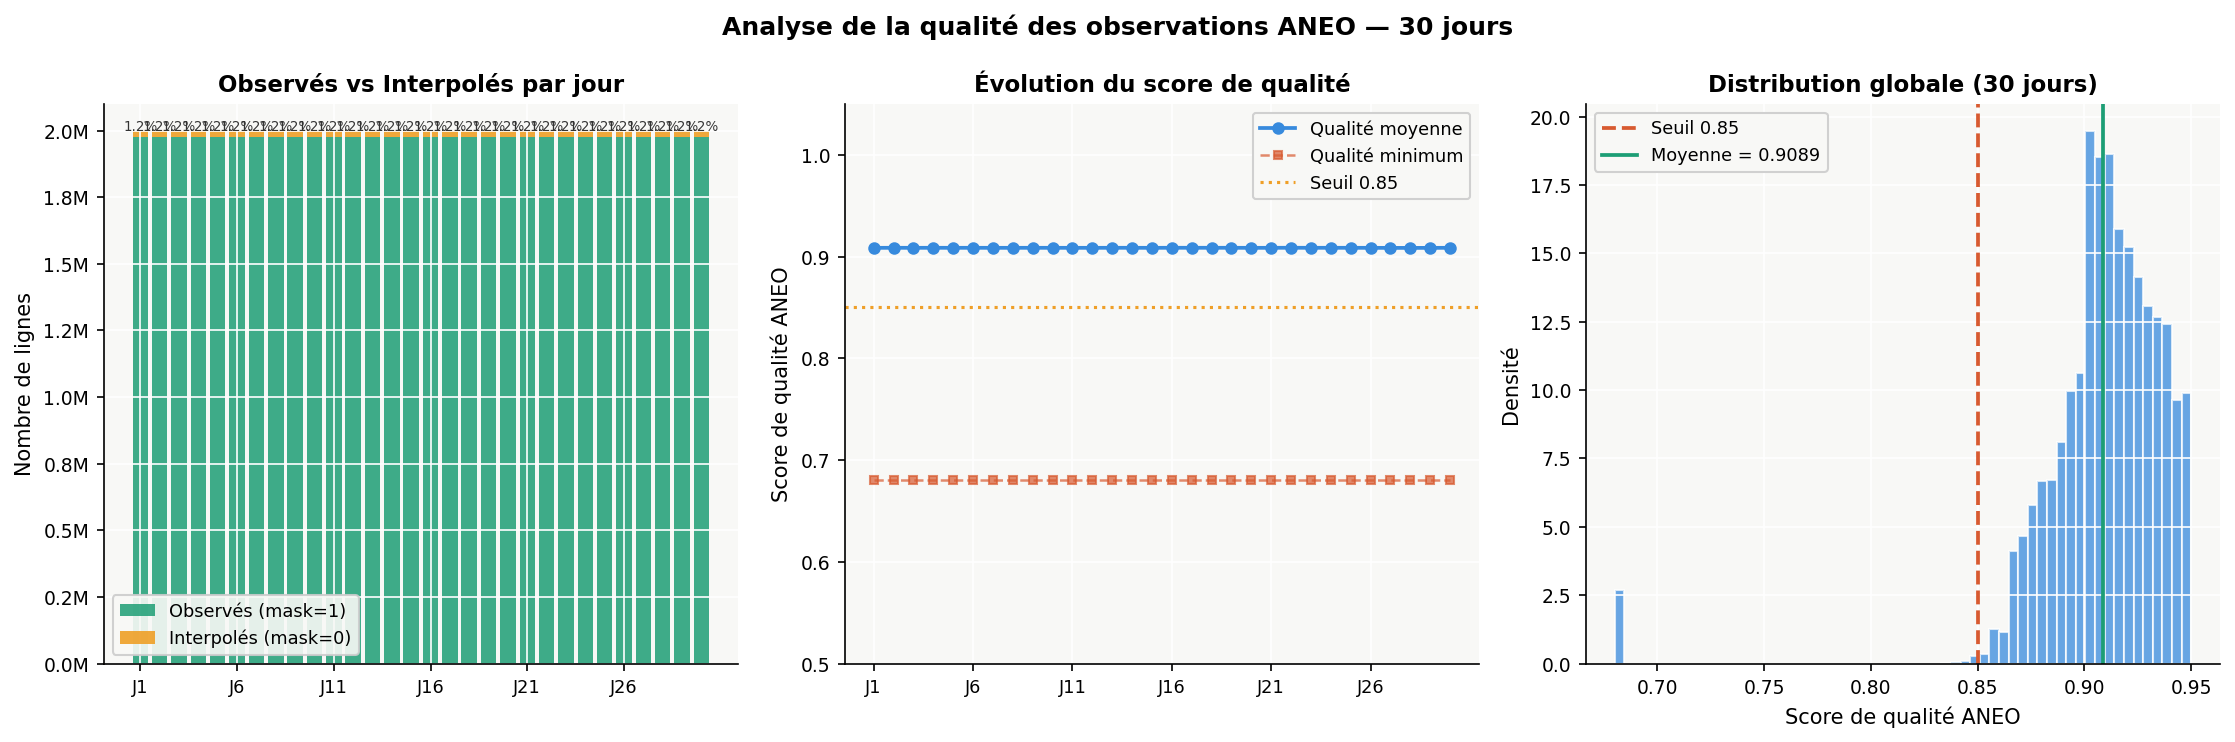

In [20]:
# ── Figure 11 : analyse de la qualité des observations ───────────────────────
days_s   = sorted(obs_dict.keys())
n_interp = [(obs_dict[d]["mask_i_obs"] == 0).sum() for d in days_s]
n_obs    = [(obs_dict[d]["mask_i_obs"] == 1).sum() for d in days_s]
q_means  = [obs_dict[d]["aneo_quality_score"].mean() for d in days_s]
q_mins   = [obs_dict[d]["aneo_quality_score"].min()  for d in days_s]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.suptitle(
    "Analyse de la qualité des observations ANEO — 30 jours",
    fontsize=12, fontweight="bold"
)

x = np.arange(len(days_s))

# ── Gauche : stacked bar observés vs interpolés ───────────────────────────────
ax = axes[0]
ax.bar(x, n_obs, color="#1D9E75", alpha=0.85,
       label="Observés (mask=1)")
ax.bar(x, n_interp, bottom=n_obs,
       color="#EF9F27", alpha=0.90,
       label="Interpolés (mask=0)")
ax.set_xticks(x[::5])
ax.set_xticklabels(
    [f"J{days_s[i]}" for i in range(0, len(days_s), 5)],
    fontsize=8.5
)
ax.set_ylabel("Nombre de lignes")
ax.set_title("Observés vs Interpolés par jour")
ax.legend(fontsize=8.5)
ax.yaxis.set_major_formatter(
    mticker.FuncFormatter(lambda v, _: f"{v/1e6:.1f}M")
)
for i, n in enumerate(n_interp):
    ax.text(i, n_obs[i] + n + 2000,
            f"{n/2e6*100:.1f}%",
            ha="center", fontsize=6.5, color="#333")

# ── Centre : évolution du score de qualité ────────────────────────────────────
ax2 = axes[1]
ax2.plot(x, q_means, "o-", color="#378ADD", lw=1.8,
         markersize=5, label="Qualité moyenne")
ax2.plot(x, q_mins, "s--", color="#D85A30", lw=1.2,
         markersize=4, alpha=0.7, label="Qualité minimum")
ax2.axhline(0.85, color="#EF9F27", ls=":", lw=1.5,
            label="Seuil 0.85")
ax2.set_xticks(x[::5])
ax2.set_xticklabels(
    [f"J{days_s[i]}" for i in range(0, len(days_s), 5)],
    fontsize=8.5
)
ax2.set_ylabel("Score de qualité ANEO")
ax2.set_title("Évolution du score de qualité")
ax2.set_ylim(0.5, 1.05)
ax2.legend(fontsize=8.5)

# ── Droite : histogramme global du score de qualité ──────────────────────────
ax3 = axes[2]
q_all = pd.concat(
    [obs_dict[d]["aneo_quality_score"].sample(
        n=5_000, random_state=42) for d in days_s],
    ignore_index=True
)
ax3.hist(q_all, bins=60, color="#378ADD", alpha=0.75,
         edgecolor="white", density=True)
ax3.axvline(0.85, color="#D85A30", lw=1.8, ls="--",
            label="Seuil 0.85")
ax3.axvline(q_all.mean(), color="#1D9E75", lw=1.8, ls="-",
            label=f"Moyenne = {q_all.mean():.4f}")
ax3.set_xlabel("Score de qualité ANEO")
ax3.set_ylabel("Densité")
ax3.set_title("Distribution globale (30 jours)")
ax3.legend(fontsize=8.5)

plt.tight_layout()
plt.savefig(OUT_DIR / "11_quality_analysis.png", dpi=150,
            bbox_inches="tight", facecolor="white")
plt.show()

Data cleaning 

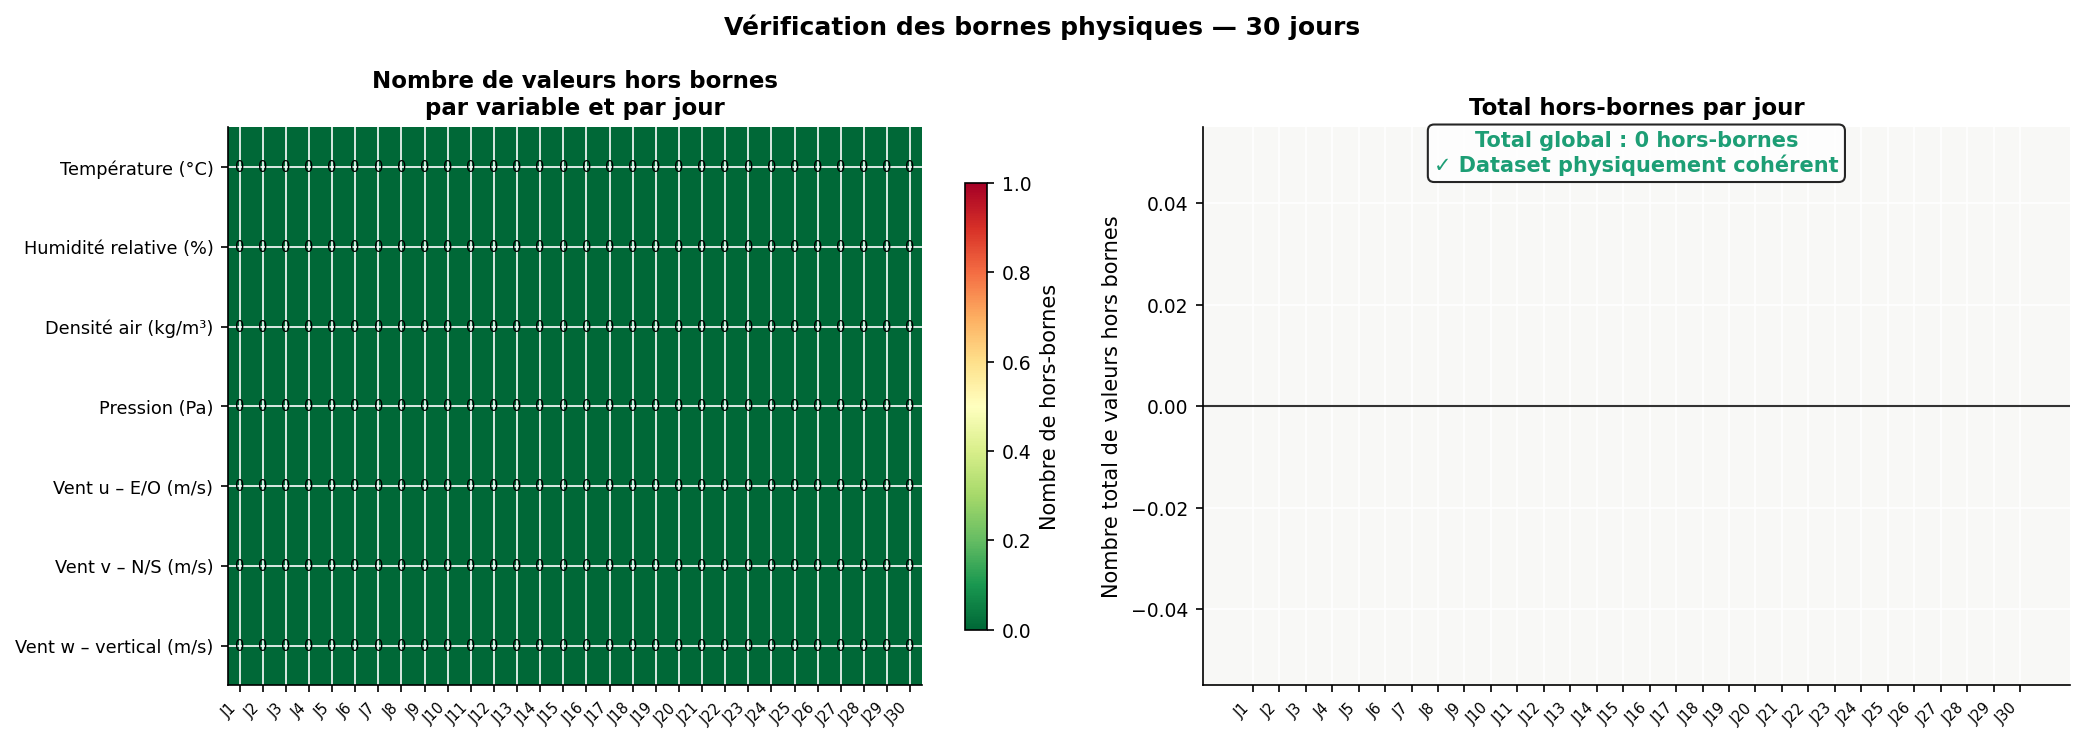

In [21]:
# ── Figure 12 : vérification des bornes physiques sur 30 jours ───────────────

# Bornes physiques acceptables pour chaque variable
bounds = {
    "temperature_c":          (-10,    55),
    "relative_humidity_pct":  (  0,   100),
    "air_density_kg_m3":      (  0.9,  1.4),
    "pressure_pa":            (80000, 110000),
    "wind_u_m_s":             (-60,    60),
    "wind_v_m_s":             (-60,    60),
    "wind_w_m_s":             (-10,    10),
}

# Calcul du nombre de hors-bornes par variable et par jour
results = []
for day, df in sorted(obs_dict.items()):
    row = {"day": day}
    for col, (lo, hi) in bounds.items():
        n_out = ((df[col] < lo) | (df[col] > hi)).sum()
        row[col] = n_out
    row["total"] = sum(row[col] for col in bounds)
    results.append(row)

df_bounds = pd.DataFrame(results).set_index("day")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle(
    "Vérification des bornes physiques — 30 jours",
    fontsize=12, fontweight="bold"
)

# ── Gauche : heatmap hors-bornes par variable × jour ─────────────────────────
ax = axes[0]
data_hm = df_bounds[list(bounds.keys())].T.values

im = ax.imshow(
    data_hm, aspect="auto",
    cmap="RdYlGn_r",
    vmin=0, vmax=max(1, data_hm.max())
)
ax.set_xticks(range(len(df_bounds)))
ax.set_xticklabels(
    [f"J{d}" for d in df_bounds.index],
    rotation=45, ha="right", fontsize=7
)
ax.set_yticks(range(len(bounds)))
ax.set_yticklabels(
    [PHYS_LABELS[c] for c in bounds.keys()],
    fontsize=8.5
)
ax.set_title("Nombre de valeurs hors bornes\npar variable et par jour")
plt.colorbar(im, ax=ax, label="Nombre de hors-bornes", shrink=0.8)

# Annoter chaque cellule
for i in range(data_hm.shape[0]):
    for j in range(data_hm.shape[1]):
        ax.text(j, i, str(int(data_hm[i, j])),
                ha="center", va="center", fontsize=7,
                color="white" if data_hm[i, j] > 0 else "black")

# ── Droite : total hors-bornes par jour ──────────────────────────────────────
ax2 = axes[1]
totals = df_bounds["total"].values
colors_bar = ["#1D9E75" if t == 0 else "#D85A30" for t in totals]

bars = ax2.bar(
    range(len(df_bounds)), totals,
    color=colors_bar, edgecolor="white", lw=0.5
)
ax2.set_xticks(range(len(df_bounds)))
ax2.set_xticklabels(
    [f"J{d}" for d in df_bounds.index],
    rotation=45, ha="right", fontsize=7
)
ax2.set_ylabel("Nombre total de valeurs hors bornes")
ax2.set_title("Total hors-bornes par jour")
ax2.axhline(0, color="#333", lw=1)

# Annotation résultat global
total_global = totals.sum()
ax2.text(
    0.5, 0.92,
    f"Total global : {total_global} hors-bornes\n"
    f"{'✓ Dataset physiquement cohérent' if total_global == 0 else '⚠ Anomalies détectées'}",
    transform=ax2.transAxes, ha="center", fontsize=10,
    fontweight="bold",
    color="#1D9E75" if total_global == 0 else "#D85A30",
    bbox=dict(boxstyle="round", fc="white", alpha=0.85)
)

plt.tight_layout()
plt.savefig(OUT_DIR / "12_bounds_check.png", dpi=150,
            bbox_inches="tight", facecolor="white")
plt.show()

In [22]:
# ── Cleaning complet et robuste — détection + correction ─────────────────────

def clean_day(df, day, bounds, phys_cols):
    """
    Applique le pipeline de cleaning complet sur un jour d'observations.
    
    Étapes :
    1. Détection et suppression des doublons
    2. Détection et correction des valeurs manquantes
    3. Détection et correction des valeurs hors bornes physiques
    4. Flaggage des points interpolés (mask_i_obs = 0)
    
    Retourne :
    - df_clean   : DataFrame nettoyé
    - rapport    : dict résumant toutes les opérations effectuées
    """
    rapport = {
        "day":            day,
        "n_initial":      len(df),
        "n_doublons":     0,
        "n_missing":      0,
        "n_hors_bornes":  0,
        "n_corriges":     0,
        "n_interpoles":   0,
        "n_final":        0,
        "colonnes_miss":  [],
        "colonnes_hors":  [],
    }

    df = df.copy()

    # ── Étape 1 : suppression des doublons ───────────────────────────────────
    n_avant = len(df)
    df = df.drop_duplicates(subset=["point_id", "timestamp_utc"])
    rapport["n_doublons"] = n_avant - len(df)

    # ── Étape 2 : valeurs manquantes ─────────────────────────────────────────
    for col in phys_cols:
        n_null = df[col].isnull().sum()
        if n_null > 0:
            rapport["n_missing"]    += n_null
            rapport["colonnes_miss"].append(f"{col}({n_null})")
            # Correction : remplacer par la médiane du jour
            mediane = df[col].median()
            df[col] = df[col].fillna(mediane)
            rapport["n_corriges"] += n_null

    # ── Étape 3 : valeurs hors bornes physiques ───────────────────────────────
    for col, (lo, hi) in bounds.items():
        masque_hors = (df[col] < lo) | (df[col] > hi)
        n_hors = masque_hors.sum()
        if n_hors > 0:
            rapport["n_hors_bornes"]  += n_hors
            rapport["colonnes_hors"].append(f"{col}({n_hors})")
            # Correction : clipper aux bornes physiques
            df[col] = df[col].clip(lo, hi)
            rapport["n_corriges"] += n_hors

    # ── Étape 4 : flaggage des points interpolés ──────────────────────────────
    rapport["n_interpoles"] = (df["mask_i_obs"] == 0).sum()

    # Ajouter un poids pour la loss function FNO
    # Points observés  (mask=1) → poids 1.0
    # Points interpolés (mask=0) → poids 0.5
    df["sample_weight"] = df["mask_i_obs"].map({1: 1.0, 0: 0.5})

    # Flaggage qualité basse
    df["low_quality"] = (df["aneo_quality_score"] < 0.85).astype(int)

    rapport["n_final"] = len(df)
    return df, rapport


# ── Application sur tous les jours ───────────────────────────────────────────
print("Application du cleaning sur les 30 jours...\n")

obs_clean  = {}   # dictionnaire des jours nettoyés
rapports   = []   # liste des rapports par jour

for day, df in sorted(obs_dict.items()):
    df_clean, rapport = clean_day(df, day, bounds, PHYS_COLS)
    obs_clean[day]    = df_clean
    rapports.append(rapport)

    # Affichage résumé par jour
    status = "✓" if (rapport["n_doublons"] == 0 and
                     rapport["n_missing"]   == 0 and
                     rapport["n_hors_bornes"] == 0) else "⚠"
    print(
        f"  {status} Jour {day:3d} | "
        f"doublons={rapport['n_doublons']} | "
        f"manquants={rapport['n_missing']} | "
        f"hors-bornes={rapport['n_hors_bornes']} | "
        f"interpolés={rapport['n_interpoles']:,} | "
        f"corrigés={rapport['n_corriges']}"
    )

df_rapports = pd.DataFrame(rapports).set_index("day")
print(f"\nCleaning terminé — {len(obs_clean)} jours traités")
print(f"Total lignes corrigées : {df_rapports['n_corriges'].sum()}")
print(f"Total doublons supprimés : {df_rapports['n_doublons'].sum()}")

Application du cleaning sur les 30 jours...

  ✓ Jour   1 | doublons=0 | manquants=0 | hors-bornes=0 | interpolés=24,019 | corrigés=0
  ✓ Jour   2 | doublons=0 | manquants=0 | hors-bornes=0 | interpolés=23,981 | corrigés=0
  ✓ Jour   3 | doublons=0 | manquants=0 | hors-bornes=0 | interpolés=24,189 | corrigés=0
  ✓ Jour   4 | doublons=0 | manquants=0 | hors-bornes=0 | interpolés=23,861 | corrigés=0
  ✓ Jour   5 | doublons=0 | manquants=0 | hors-bornes=0 | interpolés=24,225 | corrigés=0
  ✓ Jour   6 | doublons=0 | manquants=0 | hors-bornes=0 | interpolés=23,854 | corrigés=0
  ✓ Jour   7 | doublons=0 | manquants=0 | hors-bornes=0 | interpolés=24,375 | corrigés=0
  ✓ Jour   8 | doublons=0 | manquants=0 | hors-bornes=0 | interpolés=24,137 | corrigés=0
  ✓ Jour   9 | doublons=0 | manquants=0 | hors-bornes=0 | interpolés=24,017 | corrigés=0
  ✓ Jour  10 | doublons=0 | manquants=0 | hors-bornes=0 | interpolés=24,097 | corrigés=0
  ✓ Jour  11 | doublons=0 | manquants=0 | hors-bornes=0 | interpo

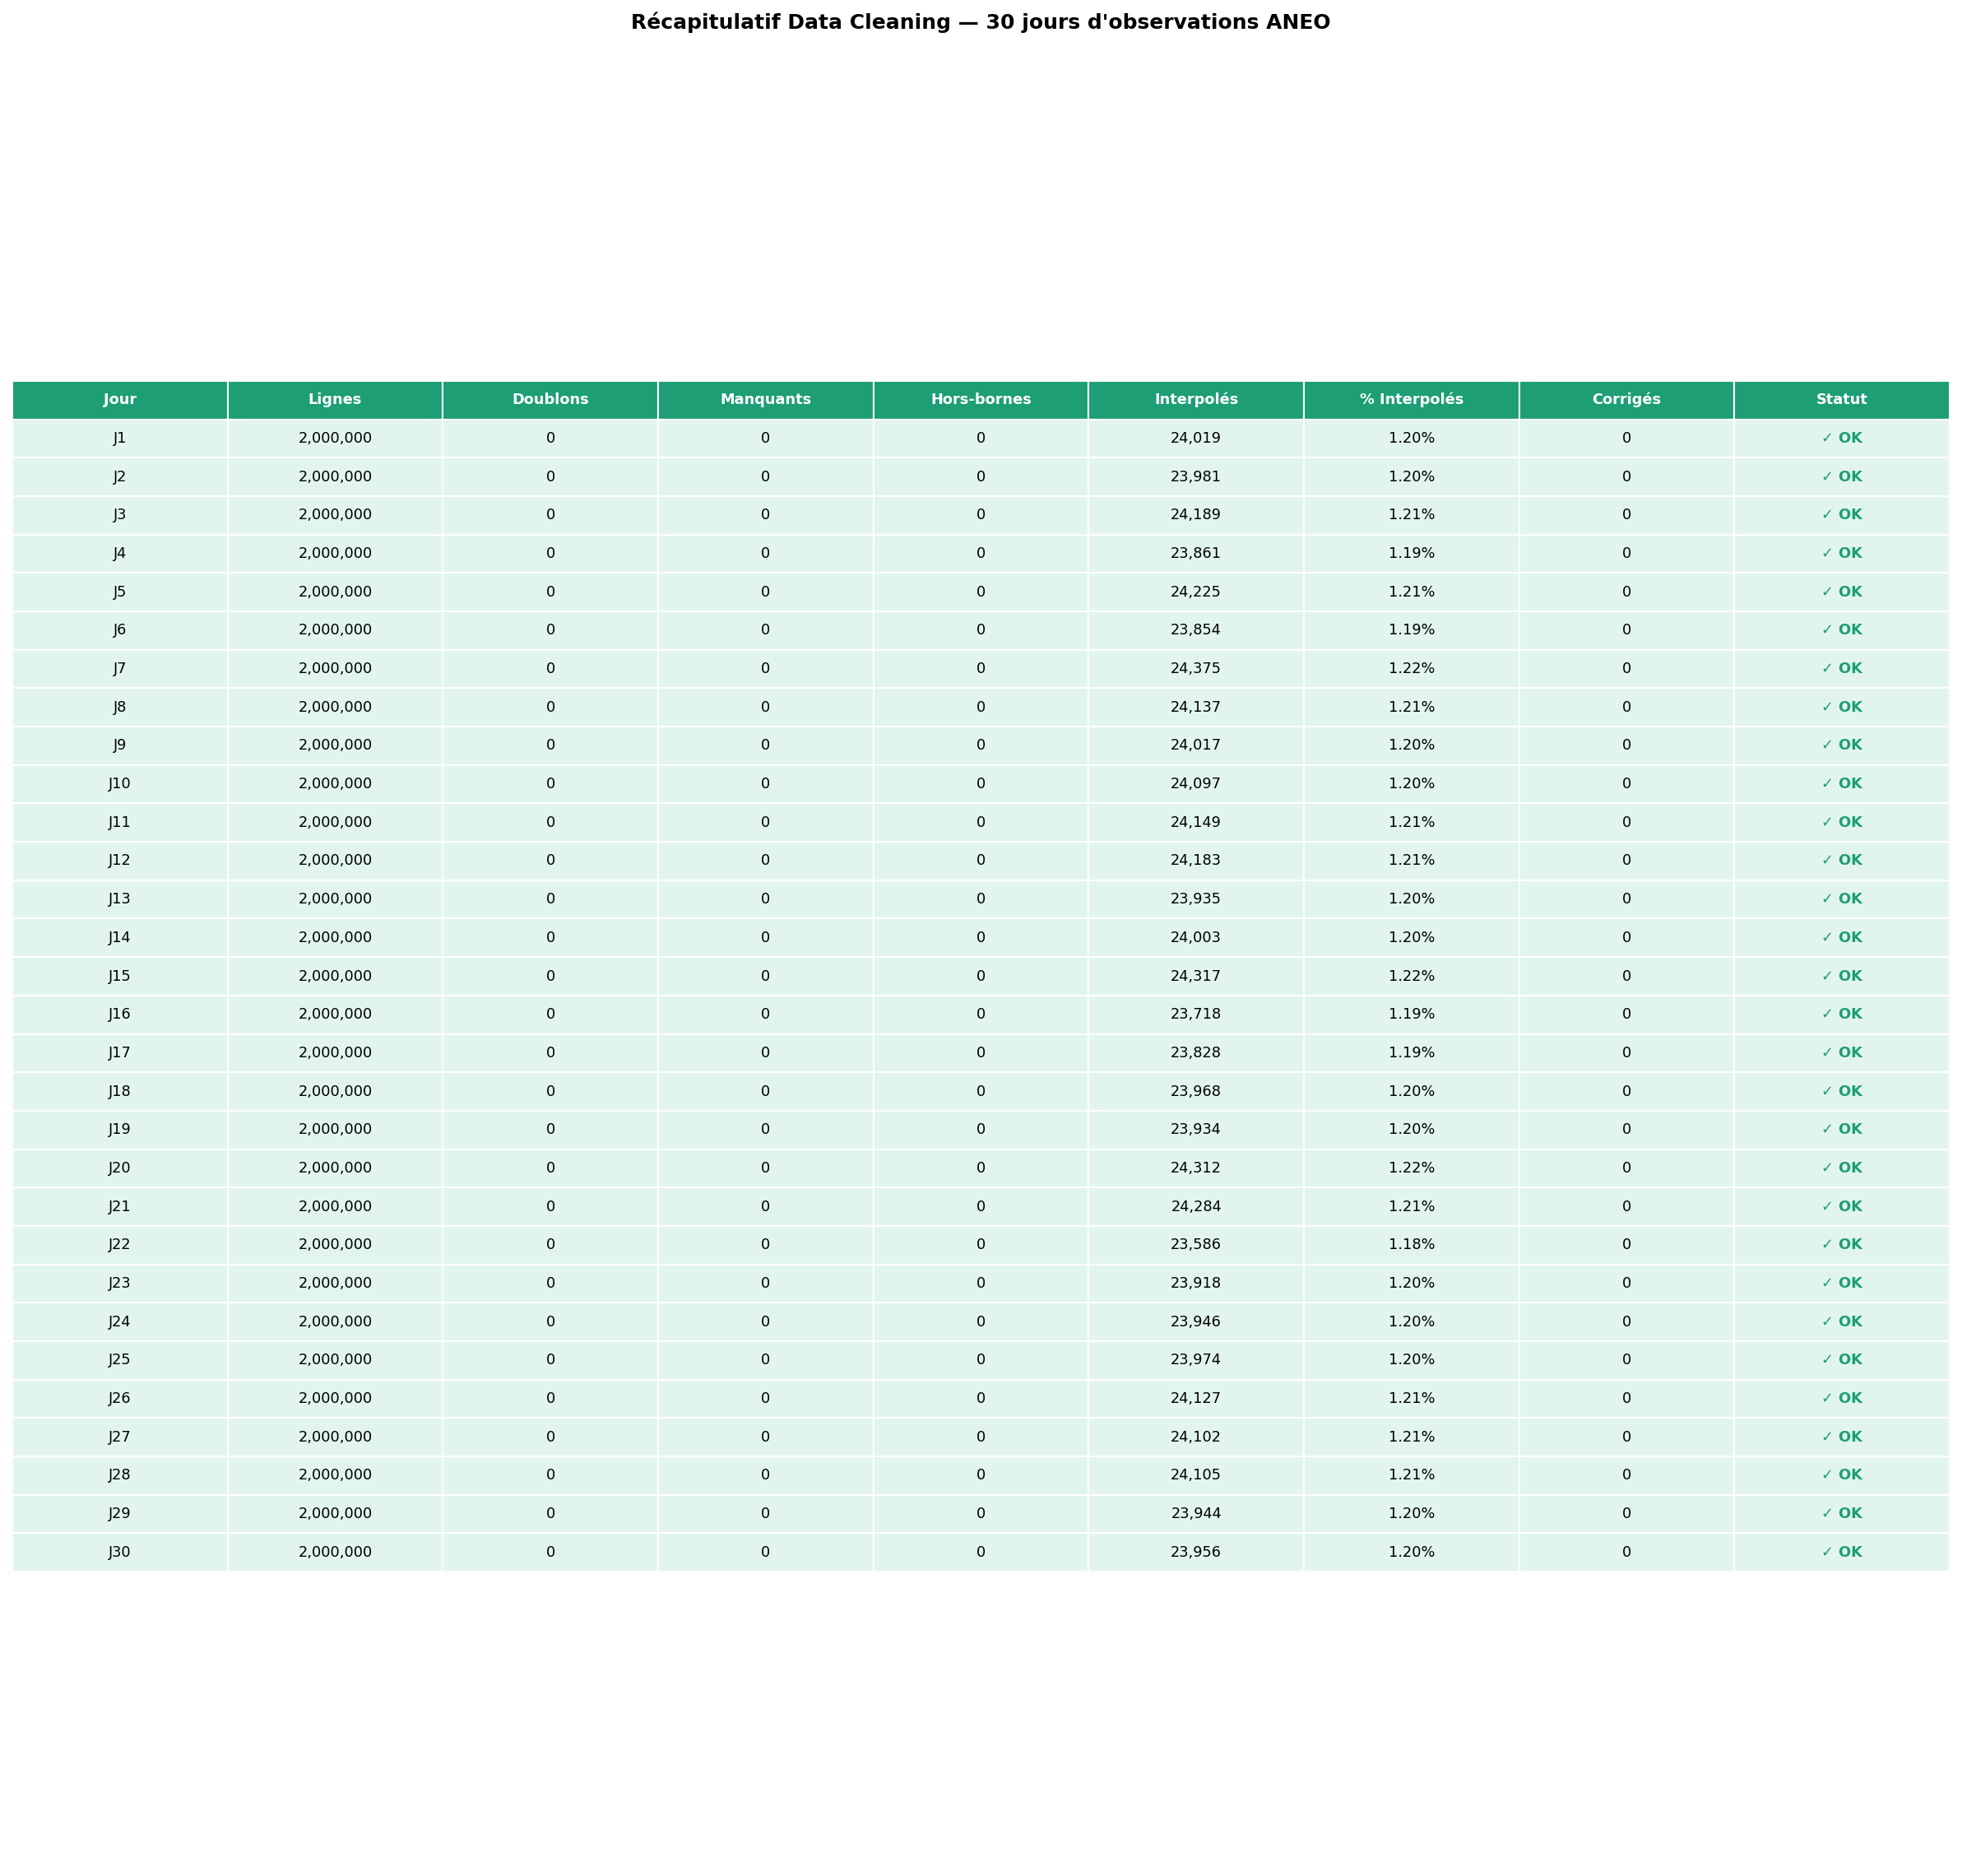

In [23]:
# ── Figure 13 : tableau récapitulatif du data cleaning ───────────────────────

fig, ax = plt.subplots(figsize=(16, len(rapports) * 0.45 + 1.5))
ax.axis("off")
fig.suptitle(
    "Récapitulatif Data Cleaning — 30 jours d'observations ANEO",
    fontsize=12, fontweight="bold", y=1.01
)

# Préparer les données du tableau
table_data = []
for r in rapports:
    status = "✓ OK" if (r["n_doublons"]    == 0 and
                        r["n_missing"]     == 0 and
                        r["n_hors_bornes"] == 0) else "⚠ Corrigé"
    table_data.append([
        f"J{r['day']}",
        f"{r['n_initial']:,}",
        str(r["n_doublons"]),
        str(r["n_missing"]),
        str(r["n_hors_bornes"]),
        f"{r['n_interpoles']:,}",
        f"{r['n_interpoles']/r['n_initial']*100:.2f}%",
        str(r["n_corriges"]),
        status,
    ])

col_labels = [
    "Jour", "Lignes", "Doublons",
    "Manquants", "Hors-bornes", "Interpolés",
    "% Interpolés", "Corrigés", "Statut"
]

table = ax.table(
    cellText=table_data,
    colLabels=col_labels,
    loc="center",
    cellLoc="center"
)
table.auto_set_font_size(False)
table.set_fontsize(8.5)
table.scale(1, 1.5)

for (row_i, col_i), cell in table.get_celld().items():
    cell.set_edgecolor("white")
    if row_i == 0:
        # En-tête vert
        cell.set_facecolor("#1D9E75")
        cell.set_text_props(color="white", fontweight="bold")
    else:
        statut = table_data[row_i - 1][-1]
        if statut == "✓ OK":
            cell.set_facecolor("#E1F5EE")
        else:
            cell.set_facecolor("#FAEEDA")
        # Colonne statut en couleur
        if col_i == len(col_labels) - 1:
            if statut == "✓ OK":
                cell.set_text_props(color="#1D9E75", fontweight="bold")
            else:
                cell.set_text_props(color="#D85A30", fontweight="bold")

plt.tight_layout()
plt.savefig(OUT_DIR / "13_cleaning_summary.png", dpi=150,
            bbox_inches="tight", facecolor="white")
plt.show()

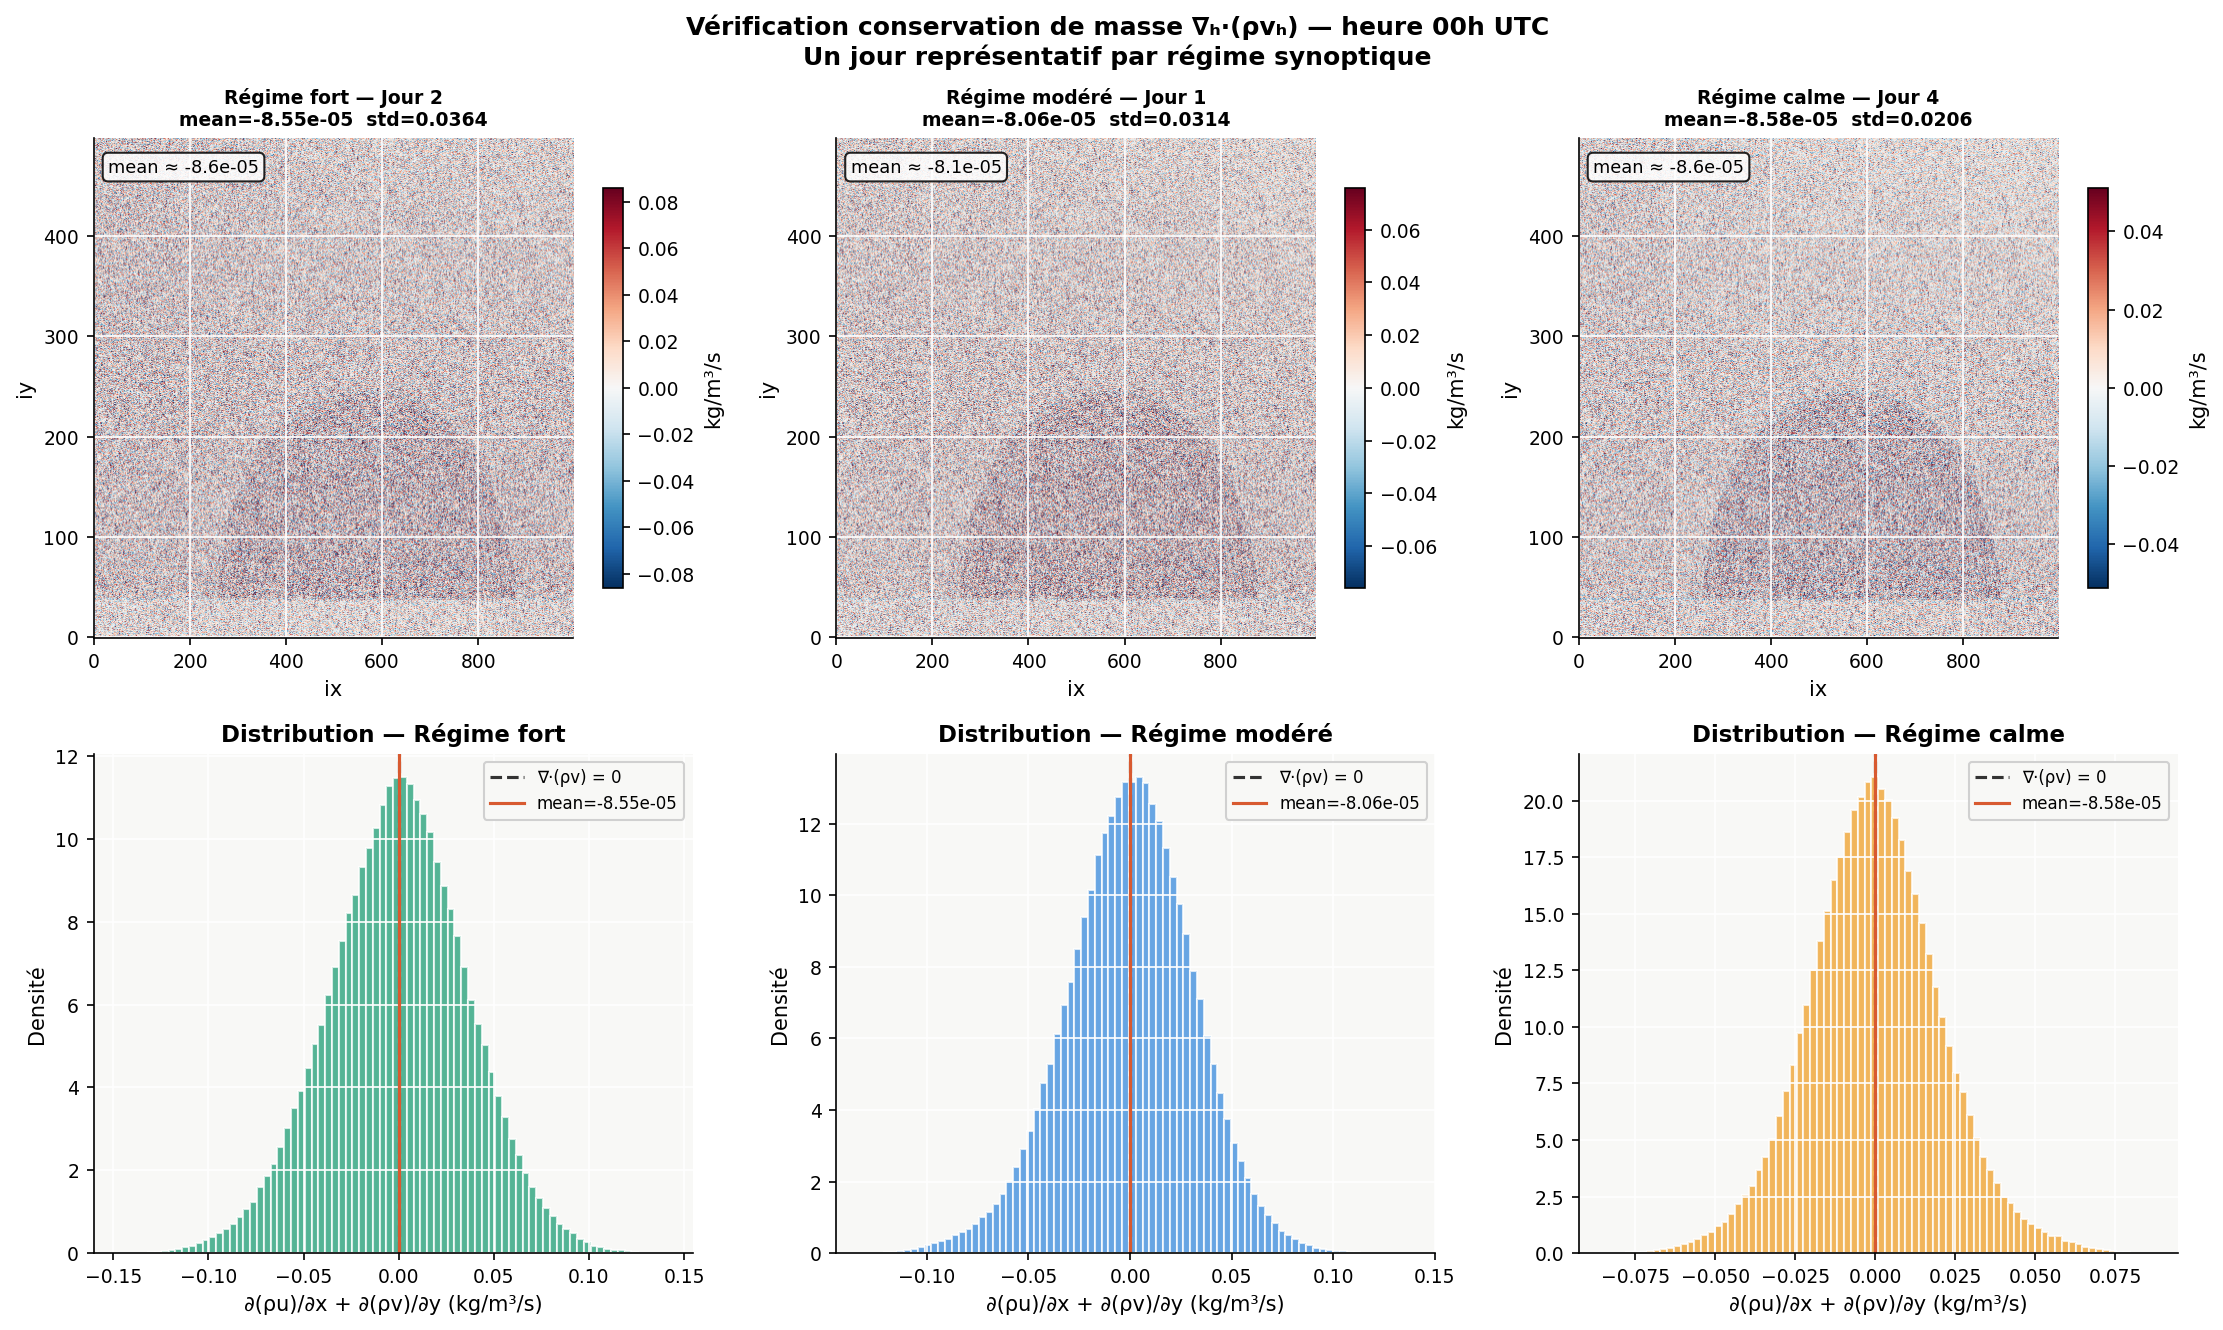

In [24]:
# ── Figure 14 : vérification de la conservation de masse ─────────────────────
# ∇·(ρv) = ∂(ρu)/∂x + ∂(ρv)/∂y ≈ 0
# On vérifie que le dataset respecte cette loi physique fondamentale

g  = grid[["point_id", "ix", "iy"]]
dx = 50.0   # espacement de la grille en mètres

# Un jour représentatif par régime
days_check = {}
for regime in ["fort", "modéré", "calme"]:
    for day in sorted(obs_clean.keys()):
        ws = obs_clean[day]["wind_speed_h"].mean()
        if regime == "fort"   and ws >= 6.0:
            days_check[regime] = day; break
        if regime == "modéré" and 4.5 <= ws < 6.0:
            days_check[regime] = day; break
        if regime == "calme"  and ws < 4.5:
            days_check[regime] = day; break

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
fig.suptitle(
    "Vérification conservation de masse ∇ₕ·(ρvₕ) — heure 00h UTC\n"
    "Un jour représentatif par régime synoptique",
    fontsize=12, fontweight="bold"
)

for col_idx, (regime, day) in enumerate(days_check.items()):
    df = obs_clean[day][obs_clean[day]["hour_utc"] == 0][[
        "point_id", "air_density_kg_m3",
        "wind_u_m_s", "wind_v_m_s"
    ]].merge(g, on="point_id")

    df["rho_u"] = df["air_density_kg_m3"] * df["wind_u_m_s"]
    df["rho_v"] = df["air_density_kg_m3"] * df["wind_v_m_s"]

    pu = df.pivot(index="iy", columns="ix", values="rho_u").values
    pv = df.pivot(index="iy", columns="ix", values="rho_v").values

    # Différences finies centrées
    drhou_dx = (pu[:, 2:] - pu[:, :-2]) / (2 * dx)
    drhov_dy = (pv[2:, :] - pv[:-2, :]) / (2 * dx)
    mr       = min(drhou_dx.shape[0], drhov_dy.shape[0])
    mc       = min(drhou_dx.shape[1], drhov_dy.shape[1])
    div2d    = drhou_dx[:mr, :mc] + drhov_dy[:mr, :mc]

    # ── Ligne 1 : carte de divergence ────────────────────────────────────────
    ax_map = axes[0, col_idx]
    vmax   = np.percentile(np.abs(div2d), 98)
    im     = ax_map.imshow(
        div2d, cmap="RdBu_r",
        vmin=-vmax, vmax=vmax,
        aspect="auto", origin="lower"
    )
    plt.colorbar(im, ax=ax_map,
                 label="kg/m³/s", shrink=0.8)
    ax_map.set_title(
        f"Régime {regime} — Jour {day}\n"
        f"mean={div2d.mean():.2e}  std={div2d.std():.4f}",
        fontsize=9
    )
    ax_map.set_xlabel("ix")
    ax_map.set_ylabel("iy")
    ax_map.text(
        0.03, 0.96,
        f"mean ≈ {div2d.mean():.1e}",
        transform=ax_map.transAxes,
        va="top", fontsize=8.5,
        bbox=dict(boxstyle="round", fc="white", alpha=0.85)
    )

    # ── Ligne 2 : histogramme de la divergence ────────────────────────────────
    ax_hist = axes[1, col_idx]
    ax_hist.hist(
        div2d.flatten(), bins=80,
        color=PALETTE_REGIME[regime],
        alpha=0.75, edgecolor="white",
        density=True
    )
    ax_hist.axvline(0, color="#333", lw=1.5, ls="--",
                    label="∇·(ρv) = 0")
    ax_hist.axvline(div2d.mean(), color="#D85A30", lw=1.5,
                    label=f"mean={div2d.mean():.2e}")
    ax_hist.set_xlabel("∂(ρu)/∂x + ∂(ρv)/∂y (kg/m³/s)")
    ax_hist.set_ylabel("Densité")
    ax_hist.set_title(f"Distribution — Régime {regime}")
    ax_hist.legend(fontsize=8)

plt.tight_layout()
plt.savefig(OUT_DIR / "14_mass_conservation.png", dpi=150,
            bbox_inches="tight", facecolor="white")
plt.show()

In [25]:
# ── Calcul des statistiques de normalisation sur les 30 jours ────────────────
# On utilise uniquement les points observés (mask=1) pour éviter
# de biaiser le z-score avec les points interpolés

print("Calcul des statistiques de normalisation...\n")

# Pooler un échantillon de tous les jours — points observés uniquement
norm_frames = []
for day, df in obs_clean.items():
    samp = df[df["mask_i_obs"] == 1].sample(
        n=min(10_000, len(df)), random_state=42
    )[PHYS_COLS]
    norm_frames.append(samp)

df_norm_pool = pd.concat(norm_frames, ignore_index=True)

# Statistiques de normalisation
norm_stats = pd.DataFrame({
    "mean": df_norm_pool.mean(),
    "std":  df_norm_pool.std(),
    "min":  df_norm_pool.min(),
    "max":  df_norm_pool.max(),
    "p01":  df_norm_pool.quantile(0.01),
    "p99":  df_norm_pool.quantile(0.99),
})

print("Statistiques de normalisation (points observés uniquement) :\n")
print(norm_stats.round(6).to_string())

# Sauvegarder pour utilisation lors de l'entraînement
norm_stats.to_csv(OUT_DIR / "normalization_stats.csv")
print(f"\n✓ Sauvegardé : {OUT_DIR}/normalization_stats.csv")

Calcul des statistiques de normalisation...

Statistiques de normalisation (points observés uniquement) :

                               mean          std          min            max           p01            p99
temperature_c             24.269709     3.981174     12.16980      33.891300     15.525098      31.942904
air_density_kg_m3          1.154426     0.020651      1.06222       1.209197      1.103238       1.197720
relative_humidity_pct     63.255728    14.036189     30.99060      98.778400     35.437398      91.132907
pressure_pa            99254.018946  1549.472759  90830.86300  101996.097000  95033.624560  101750.344690
wind_u_m_s                 1.569619     2.019481     -4.48780      13.953310     -1.855133       7.599479
wind_v_m_s                 4.138264     2.165132      0.17906      16.384560      0.815449      10.821232
wind_w_m_s                -0.027194     0.062441     -0.57296       0.417480     -0.270590       0.066240

✓ Sauvegardé : figures_eda/normalization_sta

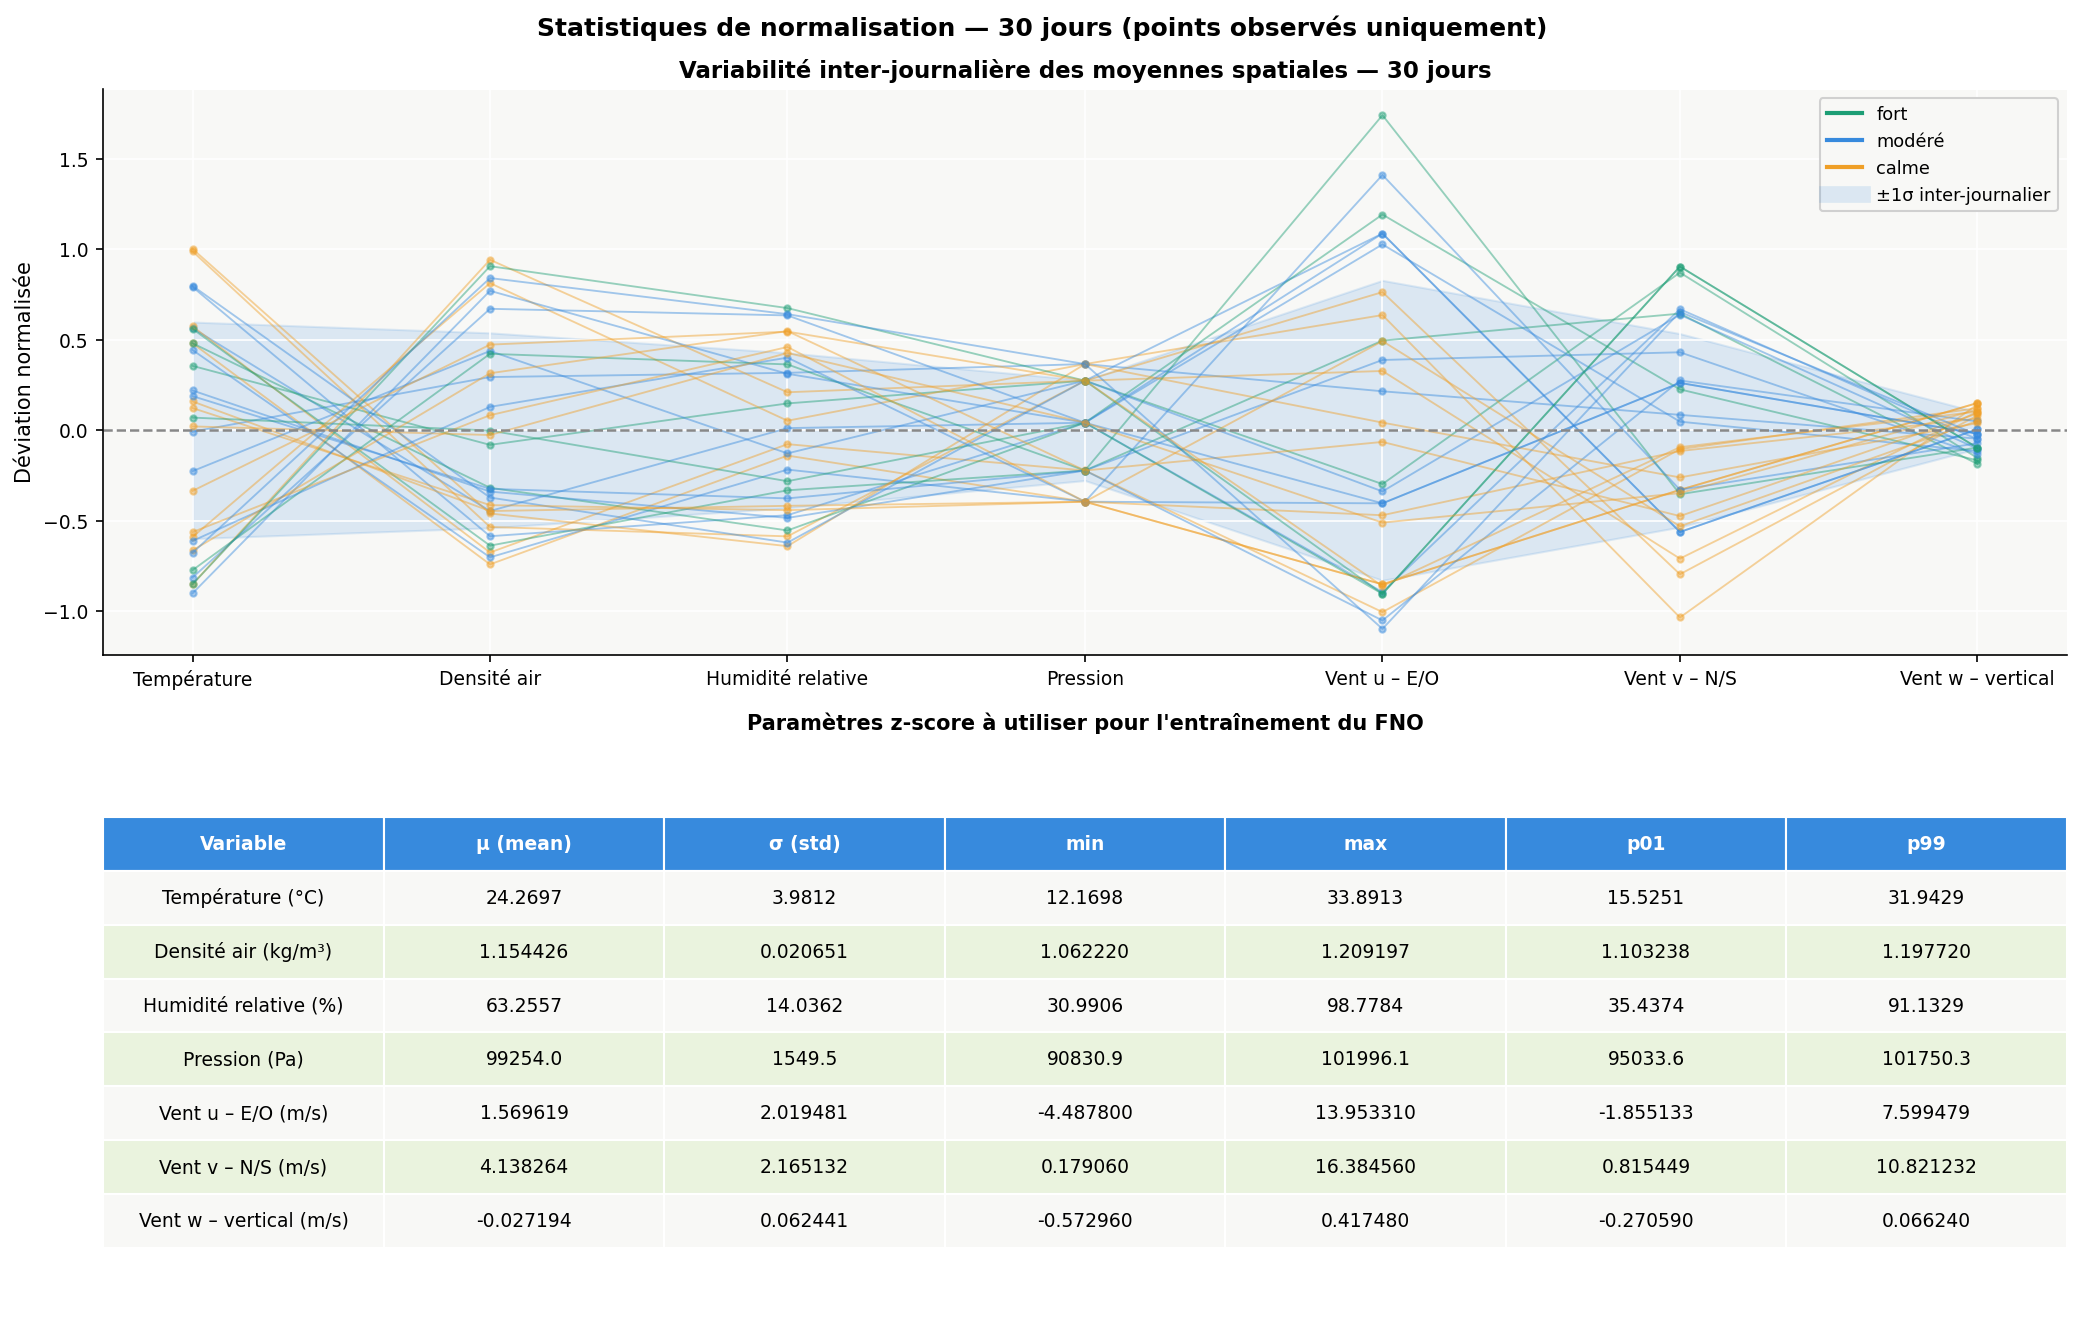

In [26]:
# ── Figure 15 : visualisation des statistiques de normalisation ───────────────

fig, axes = plt.subplots(2, 1, figsize=(14, 9))
fig.suptitle(
    "Statistiques de normalisation — 30 jours (points observés uniquement)",
    fontsize=12, fontweight="bold"
)

# ── Haut : moyenne ± std par variable et par jour ────────────────────────────
ax = axes[0]
x  = np.arange(len(PHYS_COLS))

for day, df in obs_clean.items():
    regime = meta.loc[day, "regime"]
    color  = PALETTE_REGIME[regime]
    means  = df[df["mask_i_obs"] == 1][PHYS_COLS].mean()
    # Normaliser pour affichage sur même échelle
    norm   = (means.values - norm_stats["mean"].values) / (
               norm_stats["std"].values + 1e-9)
    ax.plot(x, norm, "o-", color=color,
            lw=0.9, markersize=3, alpha=0.45)

# Bande ±1σ inter-journalière
day_means_arr = np.array([
    (obs_clean[d][obs_clean[d]["mask_i_obs"] == 1][PHYS_COLS].mean().values
     - norm_stats["mean"].values) / (norm_stats["std"].values + 1e-9)
    for d in sorted(obs_clean.keys())
])
std_band = day_means_arr.std(axis=0)
ax.fill_between(x, -std_band, +std_band,
                alpha=0.15, color="#378ADD",
                label="±1σ inter-journalier")
ax.axhline(0, color="#888", lw=1.2, ls="--")
ax.set_xticks(x)
ax.set_xticklabels(
    [PHYS_LABELS[c].split("(")[0].strip() for c in PHYS_COLS],
    fontsize=9
)
ax.set_ylabel("Déviation normalisée")
ax.set_title(
    "Variabilité inter-journalière des moyennes spatiales — 30 jours"
)

handles = [
    Line2D([0], [0], color=v, lw=2, label=k)
    for k, v in PALETTE_REGIME.items()
]
handles.append(
    Line2D([0], [0], color="#378ADD", lw=8,
           alpha=0.15, label="±1σ inter-journalier")
)
ax.legend(handles=handles, fontsize=8.5, loc="upper right")

# ── Bas : tableau μ / σ ───────────────────────────────────────────────────────
ax2 = axes[1]
ax2.axis("off")

table_data = []
for col in PHYS_COLS:
    mu  = norm_stats.loc[col, "mean"]
    sig = norm_stats.loc[col, "std"]
    mn  = norm_stats.loc[col, "min"]
    mx  = norm_stats.loc[col, "max"]
    p01 = norm_stats.loc[col, "p01"]
    p99 = norm_stats.loc[col, "p99"]

    if abs(mu) > 10_000:
        fmt = lambda v: f"{v:.1f}"
    elif abs(mu) > 10:
        fmt = lambda v: f"{v:.4f}"
    else:
        fmt = lambda v: f"{v:.6f}"

    table_data.append([
        PHYS_LABELS[col],
        fmt(mu),
        fmt(sig),
        fmt(mn),
        fmt(mx),
        fmt(p01),
        fmt(p99),
    ])

col_labels = [
    "Variable", "μ (mean)", "σ (std)",
    "min", "max", "p01", "p99"
]
table = ax2.table(
    cellText=table_data,
    colLabels=col_labels,
    loc="center",
    cellLoc="center"
)
table.auto_set_font_size(False)
table.set_fontsize(9)
table.scale(1, 1.8)

for (row_i, col_i), cell in table.get_celld().items():
    cell.set_edgecolor("white")
    if row_i == 0:
        cell.set_facecolor("#378ADD")
        cell.set_text_props(color="white", fontweight="bold")
    elif row_i % 2 == 0:
        cell.set_facecolor("#EAF3DE")
    else:
        cell.set_facecolor("#F8F8F6")

ax2.set_title(
    "Paramètres z-score à utiliser pour l'entraînement du FNO",
    fontsize=10, fontweight="bold", pad=10
)

plt.tight_layout()
plt.savefig(OUT_DIR / "15_normalization_stats.png", dpi=150,
            bbox_inches="tight", facecolor="white")
plt.show()

In [28]:
# ── Split train / validation / test ──────────────────────────────────────────
# Stratégie : split par jour en respectant la proportion des 3 régimes
# dans chaque sous-ensemble

all_days = sorted(obs_clean.keys())

# Récupérer les jours par régime
jours_fort   = [d for d in all_days if meta.loc[d, "regime"] == "fort"]
jours_modere = [d for d in all_days if meta.loc[d, "regime"] == "modéré"]
jours_calme  = [d for d in all_days if meta.loc[d, "regime"] == "calme"]

print("Jours par régime :")
print(f"  Fort   : {jours_fort}")
print(f"  Modéré : {jours_modere}")
print(f"  Calme  : {jours_calme}")

# Split 70% train / 15% val / 15% test
# On prend proportionnellement dans chaque régime
def split_regime(jours, train_r=0.70, val_r=0.15):
    n       = len(jours)
    n_train = max(1, int(n * train_r))
    n_val   = max(1, int(n * val_r))
    n_test  = n - n_train - n_val
    if n_test < 1:
        n_train -= 1
        n_test   = 1
    return (jours[:n_train],
            jours[n_train:n_train + n_val],
            jours[n_train + n_val:])

train_fort,   val_fort,   test_fort   = split_regime(jours_fort)
train_modere, val_modere, test_modere = split_regime(jours_modere)
train_calme,  val_calme,  test_calme  = split_regime(jours_calme)

train_days = sorted(train_fort + train_modere + train_calme)
val_days   = sorted(val_fort   + val_modere   + val_calme)
test_days  = sorted(test_fort  + test_modere  + test_calme)

print(f"\nSplit final :")
print(f"  Train ({len(train_days)} jours) : {train_days}")
print(f"  Val   ({len(val_days)} jours)   : {val_days}")
print(f"  Test  ({len(test_days)} jours)  : {test_days}")

print(f"\nVérification proportions :")
print(f"  Train : {len(train_days)/len(all_days)*100:.1f}%")
print(f"  Val   : {len(val_days)/len(all_days)*100:.1f}%")
print(f"  Test  : {len(test_days)/len(all_days)*100:.1f}%")

Jours par régime :
  Fort   : [2, 7, 12, 17, 22, 27]
  Modéré : [1, 3, 6, 8, 11, 13, 16, 18, 21, 23, 26, 28]
  Calme  : [4, 5, 9, 10, 14, 15, 19, 20, 24, 25, 29, 30]

Split final :
  Train (20 jours) : [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20]
  Val   (3 jours)   : [21, 22, 24]
  Test  (7 jours)  : [23, 25, 26, 27, 28, 29, 30]

Vérification proportions :
  Train : 66.7%
  Val   : 10.0%
  Test  : 23.3%


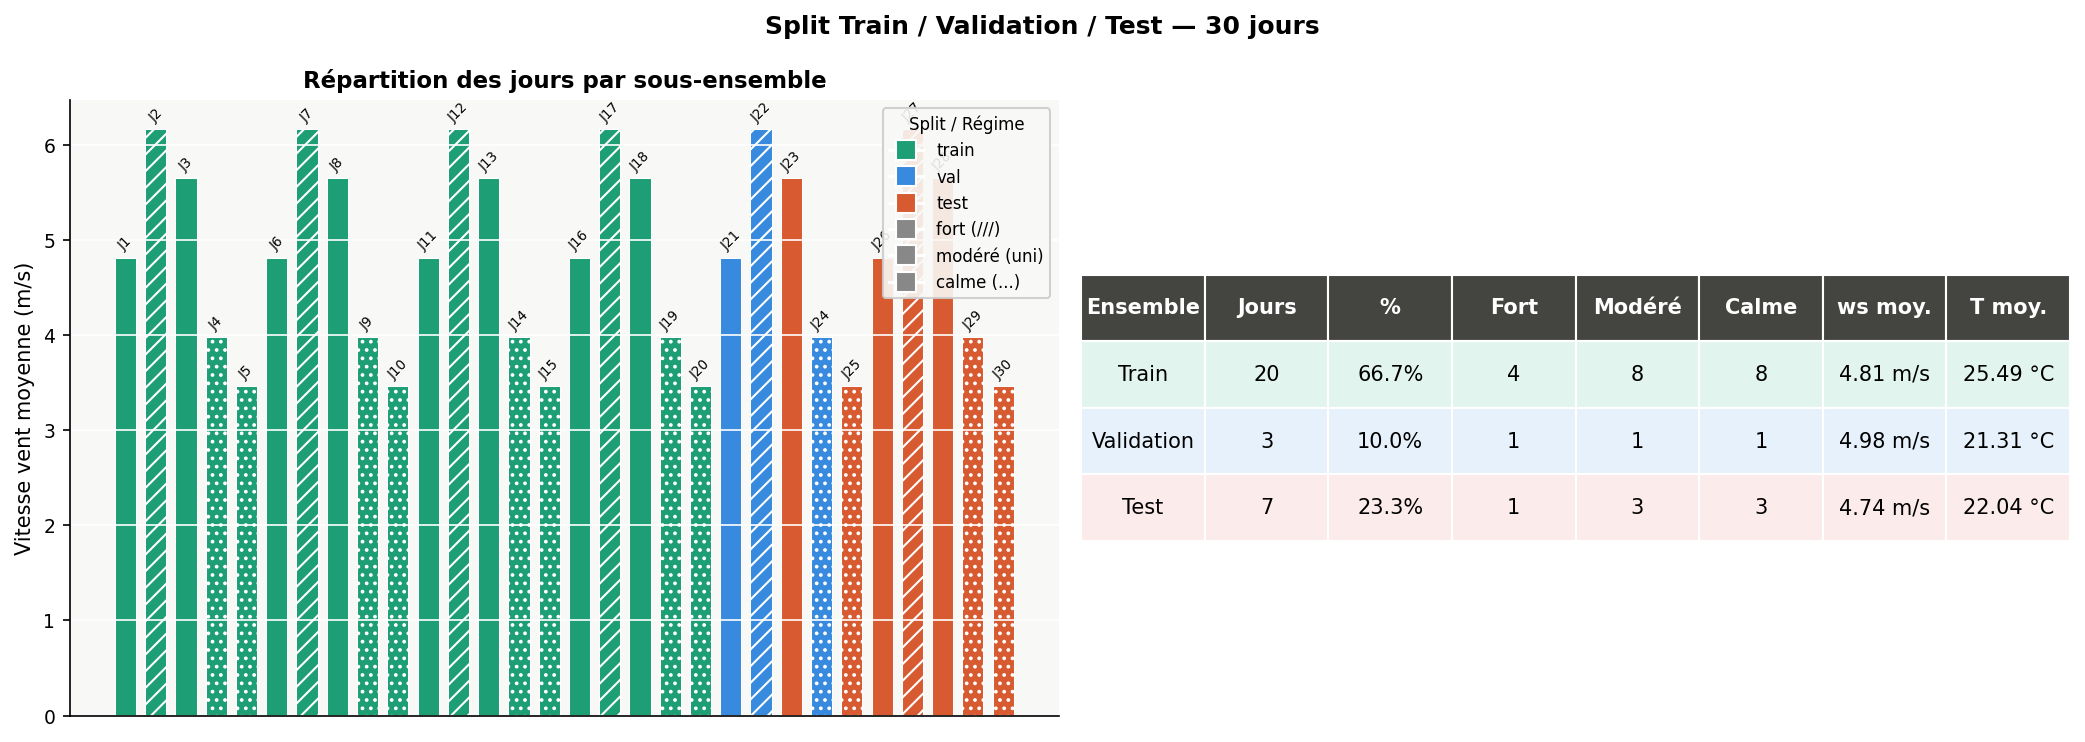

In [29]:
# ── Figure 16 : visualisation du split train / val / test ────────────────────

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle(
    "Split Train / Validation / Test — 30 jours",
    fontsize=12, fontweight="bold"
)

# ── Gauche : calendrier coloré par split ─────────────────────────────────────
ax = axes[0]

split_colors = {
    "train": "#1D9E75",
    "val":   "#378ADD",
    "test":  "#D85A30",
}

for i, day in enumerate(all_days):
    if day in train_days:
        split  = "train"
    elif day in val_days:
        split  = "val"
    else:
        split  = "test"

    regime = meta.loc[day, "regime"]
    color  = split_colors[split]

    bar = ax.bar(i, meta.loc[day, "ws_mean"],
                 color=color, width=0.7,
                 edgecolor="white", lw=0.5)

    # Hatching selon le régime
    if regime == "fort":
        bar[0].set_hatch("///")
    elif regime == "calme":
        bar[0].set_hatch("...")

    ax.text(i, meta.loc[day, "ws_mean"] + 0.05,
            f"J{day}", ha="center", va="bottom",
            fontsize=6.5, rotation=45)

ax.set_xticks([])
ax.set_ylabel("Vitesse vent moyenne (m/s)")
ax.set_title("Répartition des jours par sous-ensemble")

# Légende split
handles_split = [
    Line2D([0], [0], marker="s", color="w",
           markerfacecolor=v, markersize=10, label=k)
    for k, v in split_colors.items()
]
# Légende régime
handles_regime = [
    Line2D([0], [0], marker="s", color="w",
           markerfacecolor="#888", markersize=10,
           label="fort (///)"),
    Line2D([0], [0], marker="s", color="w",
           markerfacecolor="#888", markersize=10,
           label="modéré (uni)"),
    Line2D([0], [0], marker="s", color="w",
           markerfacecolor="#888", markersize=10,
           label="calme (...)"),
]
ax.legend(handles=handles_split + handles_regime,
          fontsize=8, loc="upper right",
          title="Split / Régime", title_fontsize=8)

# ── Droite : tableau récapitulatif du split ───────────────────────────────────
ax2 = axes[1]
ax2.axis("off")

table_data = []
for split_name, split_list in [
    ("Train", train_days),
    ("Validation", val_days),
    ("Test", test_days),
]:
    n_fort   = sum(1 for d in split_list if meta.loc[d, "regime"] == "fort")
    n_modere = sum(1 for d in split_list if meta.loc[d, "regime"] == "modéré")
    n_calme  = sum(1 for d in split_list if meta.loc[d, "regime"] == "calme")
    ws_moy   = np.mean([meta.loc[d, "ws_mean"] for d in split_list])
    t_moy    = np.mean([meta.loc[d, "T_mean"]  for d in split_list])

    table_data.append([
        split_name,
        str(len(split_list)),
        f"{len(split_list)/len(all_days)*100:.1f}%",
        str(n_fort),
        str(n_modere),
        str(n_calme),
        f"{ws_moy:.2f} m/s",
        f"{t_moy:.2f} °C",
    ])

col_labels = [
    "Ensemble", "Jours", "%",
    "Fort", "Modéré", "Calme",
    "ws moy.", "T moy."
]
table = ax2.table(
    cellText=table_data,
    colLabels=col_labels,
    loc="center",
    cellLoc="center"
)
table.auto_set_font_size(False)
table.set_fontsize(10)
table.scale(1, 2.5)

split_bg = {
    "Train":      "#E1F5EE",
    "Validation": "#E6F1FB",
    "Test":       "#FCEBEB",
}
for (row_i, col_i), cell in table.get_celld().items():
    cell.set_edgecolor("white")
    if row_i == 0:
        cell.set_facecolor("#444441")
        cell.set_text_props(color="white", fontweight="bold")
    else:
        split_name = table_data[row_i - 1][0]
        cell.set_facecolor(split_bg[split_name])

plt.tight_layout()
plt.savefig(OUT_DIR / "16_train_val_test_split.png", dpi=150,
            bbox_inches="tight", facecolor="white")
plt.show()